In [ ]:
#installations
!pip install biopython
!pip install circlify
!pip install pyahocorasick

In [ ]:
# ============================================================
# MERGE TWO FASTA FILES
# ============================================================

# Input FASTA files
fasta1 = "uniprotkb_sprot(canonical+iso).fasta"
fasta2 = "trembl_protein_struc.fasta"

# Output merged FASTA
output_file = "complete_uniprot_prot.fasta"

print("Merging FASTA files...")

with open(output_file, "w") as outfile:

    for fasta in [fasta1, fasta2]:

        with open(fasta, "r") as infile:

            for line in infile:
                outfile.write(line)

print(f"Done!\nMerged FASTA saved as: {output_file}")

In [ ]:
from Bio import SeqIO
import re
input_fasta = "complete_uniprot_prot.fasta"
isoform_fasta = "isoforms.fasta"
non_isoform_fasta = "non_isoforms.fasta"

isoforms = []
non_isoforms = []
isoform_pattern = re.compile(r"-[0-9]+\|")

for record in SeqIO.parse(input_fasta, "fasta"):
    header = record.description

    if isoform_pattern.search(header):
        isoforms.append(record)
    else:
        non_isoforms.append(record)

SeqIO.write(isoforms, isoform_fasta, "fasta")
SeqIO.write(non_isoforms, non_isoform_fasta, "fasta")

print(f"Isoforms: {len(isoforms)}")
print(f"Non-isoforms: {len(non_isoforms)}")

In [ ]:
# removing redundancy and getting accession

import csv
from tqdm import tqdm

# ================= SETTINGS =================
INPUT_FASTA = "non_isoforms.fasta"

# ONLY OUTPUT
OUTPUT_CSV = "non_isoform.csv"
# ============================================

# Store unique sequences
seen_sequences = set()

# Store unique UniProt IDs
output_rows = []

total_entries = 0
unique_entries = 0
redundant_entries = 0

# ===== READ FASTA =====
with open(INPUT_FASTA, "r") as f:

    current_header = None
    seq_parts = []

    for line in tqdm(f, desc="Reading FASTA"):

        line = line.strip()

        if line.startswith(">"):

            # Process previous entry
            if current_header is not None:

                total_entries += 1

                sequence = "".join(seq_parts)

                if sequence not in seen_sequences:

                    seen_sequences.add(sequence)
                    unique_entries += 1

                    # Extract UniProt ID
                    parts = current_header.split("|")

                    if len(parts) >= 2:
                        uniprot_id = parts[1]
                    else:
                        uniprot_id = current_header[1:].split()[0]

                    output_rows.append({
                        "accession_number": uniprot_id
                    })

                else:
                    redundant_entries += 1

            # Start next entry
            current_header = line
            seq_parts = []

        else:
            seq_parts.append(line)

    # ===== PROCESS LAST ENTRY =====
    if current_header is not None:

        total_entries += 1

        sequence = "".join(seq_parts)

        if sequence not in seen_sequences:

            seen_sequences.add(sequence)
            unique_entries += 1

            parts = current_header.split("|")

            if len(parts) >= 2:
                uniprot_id = parts[1]
            else:
                uniprot_id = current_header[1:].split()[0]

            output_rows.append({
                "accession_number": uniprot_id
            })

        else:
            redundant_entries += 1

# ===== SAVE CSV =====
with open(OUTPUT_CSV, "w", newline="") as csvfile:

    writer = csv.DictWriter(
        csvfile,
        fieldnames=["accession_number"]
    )

    writer.writeheader()
    writer.writerows(output_rows)

# ===== SUMMARY =====
print("\n===== SUMMARY =====")
print(f"Total FASTA entries:     {total_entries:,}")
print(f"Unique sequences kept:   {unique_entries:,}")
print(f"Redundant removed:       {redundant_entries:,}")

print(f"\nCSV saved → {OUTPUT_CSV}")

In [ ]:
# id mapping + pre-processing

import csv
import os
import sqlite3
import time
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
import requests
from tqdm import tqdm

# ================= SETTINGS =================
INPUT_CSV         = "non_isoform.csv"

# FINAL OUTPUT (ONLY COMPLETE DATA)
OUTPUT_CSV        = "non_isoform_comp.csv"

PROGRESS_DB       = "progress.db"
COLUMN            = "accession_number"

TOTAL_CHUNKS      = 4

UNIPROT_BATCH     = 100
UNIPROT_WORKERS   = 5
UNIPROT_DELAY     = 0.2

NCBI_BATCH        = 200
NCBI_WORKERS      = 8
NCBI_DELAY        = 0.4

TIMEOUT           = 60
MAX_RETRIES       = 5

# Values treated as missing protein IDs
NO_PROTEIN = {"", "not_found", "error", "n/a", "none", "nan", "-"}
# ============================================

OUTPUT_COLUMNS = [
    "UniProt_ID",
    "GenBank_Nucleotide_ID",
    "GenBank_Protein_ID",
    "Molecule_Type",
    "CDS_Completeness",
    "UniProt_Protein_Length",
    "NCBI_Protein_Length",
]

thread_local = threading.local()
db_lock = threading.Lock()
csv_lock = threading.Lock()

# Global NCBI rate limiter
ncbi_rate_lock = threading.Lock()
ncbi_last_req = [0.0]
NCBI_MIN_GAP = 0.11


# ─────────────────────────── SESSION ───────────────────────────
def get_session():
    if not hasattr(thread_local, "session"):
        s = requests.Session()
        s.mount(
            "https://",
            requests.adapters.HTTPAdapter(
                pool_connections=20,
                pool_maxsize=20
            )
        )
        thread_local.session = s
    return thread_local.session


# ─────────────────────────── PROGRESS DB ───────────────────────
def init_db(path):
    con = sqlite3.connect(path, check_same_thread=False)

    con.execute("""
        CREATE TABLE IF NOT EXISTS done (
            uniprot_id TEXT PRIMARY KEY,
            nuc_id TEXT,
            prot_id TEXT,
            mol_type TEXT,
            completeness TEXT,
            uniprot_length INTEGER,
            ncbi_length INTEGER
        )
    """)

    con.commit()
    return con


def load_done(con):
    return {
        r[0]
        for r in con.execute(
            "SELECT uniprot_id FROM done"
        ).fetchall()
    }


def save_rows_db(con, rows):
    with db_lock:
        con.executemany(
            """
            INSERT OR REPLACE INTO done
            (
                uniprot_id,
                nuc_id,
                prot_id,
                mol_type,
                completeness,
                uniprot_length,
                ncbi_length
            )
            VALUES (?,?,?,?,?,?,?)
            """,
            [
                (
                    r["UniProt_ID"],
                    r["GenBank_Nucleotide_ID"],
                    r["GenBank_Protein_ID"],
                    r["Molecule_Type"],
                    r["CDS_Completeness"],
                    r["UniProt_Protein_Length"],
                    r["NCBI_Protein_Length"],
                )
                for r in rows
            ]
        )

        con.commit()


# ─────────────────────────── CSV ───────────────────────────────
def init_csv(path):
    if not os.path.exists(path):
        with open(path, "w", newline="") as f:
            csv.DictWriter(
                f,
                fieldnames=OUTPUT_COLUMNS
            ).writeheader()


def append_rows_csv(path, rows):
    with csv_lock:
        with open(path, "a", newline="") as f:
            writer = csv.DictWriter(
                f,
                fieldnames=OUTPUT_COLUMNS
            )

            for row in rows:
                writer.writerow(row)


# ─────────────────────────── HELPERS ───────────────────────────
def parse_completeness(raw):

    r = (raw or "").strip().lower()

    # =========================
    # MOLECULE TYPE
    # =========================
    if "mrna" in r:
        mol = "mRNA"

    elif "genomic" in r:
        mol = "Genomic_DNA"

    elif "wgs" in r:
        mol = "WGS"

    else:
        mol = "Unclassified"

    # =========================
    # COMPLETENESS CHECK
    # =========================
    incomplete_keywords = {
        "partial",
        "incomplete",
        "truncated",
        "fragment",
        "frameshift",
        "low quality",
        "low-quality"
    }

    complete = not any(
        keyword in r
        for keyword in incomplete_keywords
    )

    return mol, complete


def select_best(refs):
    if not refs:
        return None, None, "N/A", "N/A"

    priority = {
        "mRNA": 0,
        "Genomic_DNA": 1,
        "Other": 2
    }

    best = sorted(
        refs,
        key=lambda r: (
            0 if r["complete"] else 1,
            priority.get(r["mol"], 99)
        )
    )[0]

    return (
        best["nuc"],
        best["prot"],
        best["mol"],
        "Complete" if best["complete"] else "Partial"
    )


def parse_embl(entry):
    refs = []

    for db in entry.get("uniProtKBCrossReferences", []):

        if db.get("database") != "EMBL":
            continue

        nuc = db.get("id")
        prot = ""
        mol_raw = "Unknown"

        for p in db.get("properties", []):
            if p.get("key") == "ProteinId":
                prot = p.get("value", "")

            if p.get("key") == "MoleculeType":
                mol_raw = p.get("value", "Unknown")

        if not nuc or prot == "":
            continue

        mol, complete = parse_completeness(mol_raw)

        refs.append({
            "nuc": nuc,
            "prot": prot,
            "mol": mol,
            "complete": complete
        })

    return refs


def empty_rows(uids, status):
    return [
        {
            "UniProt_ID": uid,
            "GenBank_Nucleotide_ID": status,
            "GenBank_Protein_ID": status,
            "Molecule_Type": "N/A",
            "CDS_Completeness": "N/A",
            "UniProt_Protein_Length": None,
            "NCBI_Protein_Length": None,
        }
        for uid in uids
    ]


# ─────────────────────────── UNIPROT ───────────────────────────
def fetch_uniprot_batch(uid_batch):

    time.sleep(UNIPROT_DELAY)

    url = "https://rest.uniprot.org/uniprotkb/search"

    params = {
        "query": " OR ".join(
            f"accession:{u}" for u in uid_batch
        ),
        "format": "json",
        "size": len(uid_batch),
        "fields": "accession,sequence,xref_embl",
    }

    for attempt in range(MAX_RETRIES):

        try:
            r = get_session().get(
                url,
                params=params,
                timeout=TIMEOUT
            )

            if r.status_code == 429:
                wait = 2 ** (attempt + 2)
                time.sleep(wait)
                continue

            if r.status_code != 200:
                time.sleep(3)
                continue

            found = {}

            for entry in r.json().get("results", []):

                uid = entry.get("primaryAccession", "")
                length = entry.get(
                    "sequence",
                    {}
                ).get("length")

                refs = parse_embl(entry)

                nuc, prot, mol, comp = select_best(refs)

                found[uid] = {
                    "UniProt_ID": uid,
                    "GenBank_Nucleotide_ID": nuc,
                    "GenBank_Protein_ID": prot,
                    "Molecule_Type": mol,
                    "CDS_Completeness": comp,
                    "UniProt_Protein_Length": length,
                    "NCBI_Protein_Length": None,
                }

            return [
                found.get(
                    u,
                    {
                        "UniProt_ID": u,
                        "GenBank_Nucleotide_ID": "Not_Found",
                        "GenBank_Protein_ID": "Not_Found",
                        "Molecule_Type": "N/A",
                        "CDS_Completeness": "N/A",
                        "UniProt_Protein_Length": None,
                        "NCBI_Protein_Length": None,
                    }
                )
                for u in uid_batch
            ]

        except Exception:
            time.sleep(2 ** attempt)

    return empty_rows(uid_batch, "Error")


# ─────────────────────────── NCBI ──────────────────────────────
def fetch_ncbi_batch(prot_batch):

    with ncbi_rate_lock:

        now = time.monotonic()
        gap = NCBI_MIN_GAP - (now - ncbi_last_req[0])

        if gap > 0:
            time.sleep(gap)

        ncbi_last_req[0] = time.monotonic()

    bare_map = {}

    for uid, prot in prot_batch:
        bare_map[prot.split(".")[0]] = uid

    url = (
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        f"?db=protein&id={','.join(bare_map.keys())}"
        f"&rettype=fasta&retmode=text"
        f"&api_key={NCBI_API_KEY}"
    )

    for attempt in range(MAX_RETRIES):

        try:
            r = get_session().get(
                url,
                timeout=TIMEOUT
            )

            if r.status_code == 429:
                wait = 2 ** (attempt + 2)
                time.sleep(wait)
                continue

            if r.status_code == 200:

                lengths = {}

                cur = None
                parts = []

                for line in r.text.splitlines():

                    if line.startswith(">"):

                        if cur:
                            lengths[cur] = len(
                                "".join(parts)
                            )

                        p = line[1:].split()

                        cur = (
                            p[0].split(".")[0]
                            if p else None
                        )

                        parts = []

                    else:
                        parts.append(line.strip())

                if cur:
                    lengths[cur] = len(
                        "".join(parts)
                    )

                return {
                    bare_map[bare]: lengths.get(bare)
                    for bare in bare_map
                }

            time.sleep(3)

        except Exception:
            time.sleep(2 ** attempt)

    return {
        bare_map[bare]: None
        for bare in bare_map
    }


# ─────────────────────────── PROCESS CHUNK ─────────────────────
def process_chunk(chunk_ids, chunk_num, con):

    skip = {
        "",
        "Not_Found",
        "Error",
        "N/A",
        "None",
        "nan",
        "none"
    }

    print(
        f"\n[Chunk {chunk_num}] "
        f"UniProt pass ({len(chunk_ids):,} IDs)"
    )

    batches = [
        chunk_ids[i:i + UNIPROT_BATCH]
        for i in range(
            0,
            len(chunk_ids),
            UNIPROT_BATCH
        )
    ]

    uni_rows = {}

    with ThreadPoolExecutor(
        max_workers=UNIPROT_WORKERS
    ) as ex:

        futures = {
            ex.submit(fetch_uniprot_batch, b): b
            for b in batches
        }

        for f in tqdm(
            as_completed(futures),
            total=len(futures),
            desc=f"Chunk {chunk_num} UniProt"
        ):

            for row in f.result():
                uni_rows[row["UniProt_ID"]] = row

    ncbi_pairs = [
        (uid, row["GenBank_Protein_ID"])
        for uid, row in uni_rows.items()
        if row.get("GenBank_Protein_ID")
        and str(
            row["GenBank_Protein_ID"]
        ).strip() not in skip
    ]

    print(
        f"[Chunk {chunk_num}] "
        f"NCBI pass ({len(ncbi_pairs):,} proteins)"
    )

    ncbi_lengths = {}

    if ncbi_pairs:

        batches = [
            ncbi_pairs[i:i + NCBI_BATCH]
            for i in range(
                0,
                len(ncbi_pairs),
                NCBI_BATCH
            )
        ]

        with ThreadPoolExecutor(
            max_workers=NCBI_WORKERS
        ) as ex:

            futures = {
                ex.submit(fetch_ncbi_batch, b): b
                for b in batches
            }

            for f in tqdm(
                as_completed(futures),
                total=len(futures),
                desc=f"Chunk {chunk_num} NCBI"
            ):
                ncbi_lengths.update(f.result())

    # ===== KEEP ONLY COMPLETE ROWS =====
    final_rows = []

    for uid in chunk_ids:

        row = uni_rows.get(
            uid,
            {
                "UniProt_ID": uid,
                "GenBank_Nucleotide_ID": "Error",
                "GenBank_Protein_ID": "Error",
                "Molecule_Type": "Error",
                "CDS_Completeness": "Error",
                "UniProt_Protein_Length": None,
                "NCBI_Protein_Length": None,
            }
        )

        row["NCBI_Protein_Length"] = ncbi_lengths.get(uid)

        prot_id = str(
            row["GenBank_Protein_ID"]
        ).strip().lower()

        # ONLY SAVE COMPLETE DATA
        if prot_id not in NO_PROTEIN:
            final_rows.append(row)

    if final_rows:
        save_rows_db(con, final_rows)
        append_rows_csv(OUTPUT_CSV, final_rows)

    print(
        f"[Chunk {chunk_num}] "
        f"Saved {len(final_rows):,} COMPLETE rows"
    )


# ─────────────────────────── MAIN ──────────────────────────────
def main():

    try:
        df = pd.read_csv(INPUT_CSV)

    except Exception as e:
        print(f"Error loading CSV: {e}")
        return

    all_ids = (
        df[COLUMN]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    total = len(all_ids)

    print(
        f"Total IDs: {total:,}"
    )

    con = init_db(PROGRESS_DB)

    done_set = load_done(con)

    init_csv(OUTPUT_CSV)

    print(
        f"Already done: {len(done_set):,}"
    )

    chunk_size = (
        total + TOTAL_CHUNKS - 1
    ) // TOTAL_CHUNKS

    chunks = [
        all_ids[i:i + chunk_size]
        for i in range(
            0,
            total,
            chunk_size
        )
    ]

    for idx, chunk in enumerate(chunks):

        todo = [
            uid
            for uid in chunk
            if uid not in done_set
        ]

        print(
            f"\n━━━ Chunk {idx+1}/{TOTAL_CHUNKS} "
            f"({len(todo):,} IDs) ━━━"
        )

        if not todo:
            print("Skipping")
            continue

        process_chunk(
            todo,
            idx + 1,
            con
        )

        done_set.update(todo)

        print(
            f"Progress: "
            f"{len(done_set):,}/{total:,}"
        )

    con.close()

    print(
        f"\n✓ COMPLETE DATA SAVED → "
        f"{OUTPUT_CSV}"
    )


if __name__ == "__main__":
    main()

In [ ]:
# cds extraction

import csv
import os
import sqlite3
import time
import threading
import random
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import StringIO
import requests
from Bio import SeqIO
from tqdm import tqdm

# ================= SETTINGS =================
INPUT_CSV       = "non_isoform_comp.csv"
OUTPUT_FASTA    = "non_isoform_cds_output.fasta"
FAILED_CSV      = "non_isoform_cds_failed.csv"
PROGRESS_DB     = "cds_progress.db"

WORKERS         = 4              # ↓ reduced for stability
MIN_GAP         = 0.18           # ↓ safer global rate
TIMEOUT         = 90             # ↑ better for slow responses
MAX_RETRIES     = 5

NCBI_API_KEY    = "3ab472c6ad8f89a6b587fe4efc486db18309"
# ============================================

db_lock      = threading.Lock()
fasta_lock   = threading.Lock()
failed_lock  = threading.Lock()
rate_lock    = threading.Lock()
last_req     = [0.0]

FAILED_COLUMNS = ["UniProt_ID", "GenBank_Nucleotide_ID", "GenBank_Protein_ID", "Reason"]

thread_local = threading.local()

def get_session():
    if not hasattr(thread_local, "session"):
        s = requests.Session()
        s.mount("https://", requests.adapters.HTTPAdapter(
            pool_connections=20, pool_maxsize=20, max_retries=0))
        thread_local.session = s
    return thread_local.session


def throttle():
    with rate_lock:
        now = time.monotonic()
        gap = MIN_GAP - (now - last_req[0])
        if gap > 0:
            time.sleep(gap + random.uniform(0, 0.05))  # jitter added
        last_req[0] = time.monotonic()


# ─────────────────────────── DB ───────────────────────────
def init_db(path):
    con = sqlite3.connect(path, check_same_thread=False)
    con.execute("""
        CREATE TABLE IF NOT EXISTS done (
            uniprot_id TEXT PRIMARY KEY,
            status TEXT
        )
    """)
    con.commit()
    return con

def load_done(con):
    return {r[0] for r in con.execute("SELECT uniprot_id FROM done").fetchall()}

def mark_done(con, uid, status):
    with db_lock:
        con.execute("INSERT OR REPLACE INTO done VALUES (?,?)", (uid, status))
        con.commit()


# ─────────────────────────── OUTPUT ───────────────────────────
def init_fasta(path):
    if not os.path.exists(path):
        open(path, "w").close()

def write_fasta(path, row, seq):
    header = ">" + "|".join(str(v).split(".")[0] for v in row.values())
    with fasta_lock:
        with open(path, "a") as f:
            f.write(f"{header}\n{seq}\n")

def init_failed(path):
    if not os.path.exists(path):
        with open(path, "w", newline="") as f:
            csv.DictWriter(f, fieldnames=FAILED_COLUMNS).writeheader()

def write_failed(path, row):
    with failed_lock:
        with open(path, "a", newline="") as f:
            csv.DictWriter(f, fieldnames=FAILED_COLUMNS).writerow(row)


# ─────────────────────────── REQUEST ───────────────────────────
def ncbi_get(url):
    for attempt in range(MAX_RETRIES):
        try:
            throttle()
            r = get_session().get(url, timeout=TIMEOUT)

            if r.status_code == 429:
                wait = 2 ** (attempt + 2)
                tqdm.write(f"[429] sleeping {wait}s")
                time.sleep(wait)
                continue

            return r

        except Exception as e:
            if attempt < MAX_RETRIES - 1:
                tqdm.write(f"[conn err] retry {attempt+1}: {e}")
                time.sleep(2 ** attempt)
            else:
                raise

    raise Exception("Max retries exceeded")


# ─────────────────────────── FETCH ───────────────────────────
def fetch_via_protein(prot_id):
    bare = prot_id.split(".")[0]

    url = (
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        f"?db=protein&id={bare}&rettype=fasta_cds_na&retmode=text"
        f"&api_key={NCBI_API_KEY}"
    )

    r = ncbi_get(url)

    if r.status_code != 200:
        return None, f"HTTP {r.status_code}"

    seq = "".join(
        line.strip() for line in r.text.splitlines()
        if line and not line.startswith(">")
    )

    if seq:
        return seq, None

    return None, "Empty sequence"


def fetch_via_nuccore(nuc_id, prot_id):
    bare = prot_id.split(".")[0]

    url = (
        "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        f"?db=nuccore&id={nuc_id}&rettype=gb&retmode=text"
        f"&api_key={NCBI_API_KEY}"
    )

    r = ncbi_get(url)

    if r.status_code != 200:
        return None, f"HTTP {r.status_code}"

    try:
        record = SeqIO.read(StringIO(r.text), "genbank")
    except Exception as e:
        return None, f"Parse error: {e}"

    for f in record.features:
        if f.type == "CDS":
            for pid in f.qualifiers.get("protein_id", []):
                if pid.split(".")[0] == bare:
                    try:
                        return str(f.extract(record.seq)), None
                    except:
                        return None, "No embedded sequence"

    return None, "CDS not found"


# 🔥 SMART FETCH (skip useless fallback)
def fetch_cds(nuc_id, prot_id):
    seq, reason = fetch_via_protein(prot_id)

    if seq:
        return seq, None

    # 🚀 skip known useless cases
    if reason and ("400" in reason or "Empty" in reason):
        return None, "Skip fallback (bad protein)"

    tqdm.write(f"[fallback] {prot_id}")
    return fetch_via_nuccore(nuc_id, prot_id)


# ─────────────────────────── WORKER ───────────────────────────
def process_row(row, con):
    uid = row["UniProt_ID"]

    try:
        seq, reason = fetch_cds(
            row["GenBank_Nucleotide_ID"],
            row["GenBank_Protein_ID"]
        )
    except Exception as e:
        seq, reason = None, str(e)

    if seq:
        write_fasta(OUTPUT_FASTA, row, seq)
        mark_done(con, uid, "ok")
        return "ok"
    else:
        write_failed(FAILED_CSV, {
            "UniProt_ID": uid,
            "GenBank_Nucleotide_ID": row["GenBank_Nucleotide_ID"],
            "GenBank_Protein_ID": row["GenBank_Protein_ID"],
            "Reason": reason,
        })
        mark_done(con, uid, "failed")
        return "failed"


# ─────────────────────────── MAIN ───────────────────────────
def main():
    rows = list(csv.DictReader(open(INPUT_CSV)))

    print(f"Total rows: {len(rows):,}")

    con = init_db(PROGRESS_DB)
    done = load_done(con)

    todo = [r for r in rows if r["UniProt_ID"] not in done]

    print(f"Done: {len(done):,} | Remaining: {len(todo):,}\n")

    init_fasta(OUTPUT_FASTA)
    init_failed(FAILED_CSV)

    ok = fail = 0

    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        futures = [ex.submit(process_row, r, con) for r in todo]

        for f in tqdm(as_completed(futures), total=len(futures)):
            if f.result() == "ok":
                ok += 1
            else:
                fail += 1

    print(f"\nDone: {ok+fail:,}")
    print(f"Success: {ok:,}")
    print(f"Failed: {fail:,}")

    con.close()


if __name__ == "__main__":
    main()

In [ ]:
# creating isoform cds file

import gzip
import os
from typing import Iterator, Tuple, List, Optional
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import time
from datetime import datetime
import re

NCBI_EFETCH_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
UNIPROT_BASE_URL = "https://rest.uniprot.org/uniprotkb"
NCBI_RATE_LIMIT = 1.0

DEBUG_MODE = True
SAMPLE_SIZE = 12


class UniProtHeader:
#    """Parse UniProt FASTA header format."""
    PATTERN = re.compile(r'sp\|([A-Z0-9]+-\d+)\|')

    @staticmethod
    def extract_uniprot_id(header: str) -> Optional[str]:
        """Extract UniProt ID from FASTA header."""
        header = header.lstrip('>')
        match = UniProtHeader.PATTERN.search(header)
        if match:
            return match.group(1)
        return None


class UniProtFetcher:
#    """Fetch RefSeq NM IDs and Protein IDs from UniProt JSON."""

    def __init__(self):
        self.session = requests.Session()
        try:
            retry_strategy = Retry(
                total=3,
                status_forcelist=[429, 500, 502, 503, 504],
                allowed_methods=["GET"],
                backoff_factor=1
            )
        except TypeError:
            retry_strategy = Retry(
                total=3,
                status_forcelist=[429, 500, 502, 503, 504],
                method_whitelist=["GET"],
                backoff_factor=1
            )

        adapter = HTTPAdapter(max_retries=retry_strategy)
        self.session.mount("http://", adapter)
        self.session.mount("https://", adapter)

    def get_refseq_ids(self, uniprot_id: str, diagnostic: bool = False) -> Optional[Tuple[str, str]]:
#       """
#        Get RefSeq Protein ID (NP_) and Nucleotide ID (NM_) for a UniProt isoform ID.
#        Returns: (protein_id, nucleotide_id) or None
#      """
        try:
            url = f"{UNIPROT_BASE_URL}/{uniprot_id}.json"

            if diagnostic:
                print(f"  [DIAG] Fetching: {url}")

            response = self.session.get(url, timeout=10)

            if response.status_code != 200:
                if diagnostic:
                    print(f"  [DIAG] ❌ UniProt fetch failed with status {response.status_code}")
                return None

            if diagnostic:
                print(f"  [DIAG] ✅ UniProt response received (status 200)")

            data = response.json()

            if 'uniProtKBCrossReferences' not in data:
                if diagnostic:
                    print(f"  [DIAG] ❌ No 'uniProtKBCrossReferences' key in JSON response")
                return None

            xrefs = data['uniProtKBCrossReferences']

            if diagnostic:
                print(f"  [DIAG] ✅ Found {len(xrefs)} cross-references total")

            refseq_entries = [x for x in xrefs if x.get('database') == 'RefSeq']

            if diagnostic:
                print(f"  [DIAG] Found {len(refseq_entries)} RefSeq entries")

            if not refseq_entries:
                if diagnostic:
                    print(f"  [DIAG] ❌ No RefSeq database entries found")
                    databases = set(x.get('database') for x in xrefs)
                    print(f"  [DIAG] Available databases: {', '.join(sorted(databases))}")
                return None

            found_np_entries = []

            for idx, xref in enumerate(refseq_entries, 1):
                protein_id = xref.get('id', '')

                if diagnostic:
                    print(f"  [DIAG] Checking RefSeq entry #{idx}: {protein_id}")

                if not protein_id.startswith('NP_'):
                    if diagnostic:
                        print(f"  [DIAG]   ❌ Not NP_ format (starts with: {protein_id[:5]})")
                    continue

                found_np_entries.append(protein_id)

                nucleotide_id = None
                has_properties = 'properties' in xref

                if diagnostic:
                    print(f"  [DIAG]   ✅ NP_ format detected: {protein_id}")
                    print(f"  [DIAG]   Has properties: {has_properties}")

                if has_properties:
                    properties = xref['properties']
                    if diagnostic:
                        print(f"  [DIAG]   Properties count: {len(properties)}")

                    for prop_idx, prop in enumerate(properties, 1):
                        prop_key = prop.get('key', '')
                        prop_value = prop.get('value', '')

                        if diagnostic and prop_idx <= 5:
                            print(f"  [DIAG]     Property {prop_idx}: {prop_key} = {prop_value}")

                        if prop_key == 'NucleotideSequenceId':
                            nucleotide_id = prop_value
                            if diagnostic:
                                print(f"  [DIAG]     ✅ Found NucleotideSequenceId: {nucleotide_id}")
                            break

                if not nucleotide_id:
                    if diagnostic:
                        print(f"  [DIAG]   ❌ No NucleotideSequenceId property found")
                    continue

                if not nucleotide_id.startswith('NM_'):
                    if diagnostic:
                        print(f"  [DIAG]   ❌ NucleotideSequenceId not NM_ format: {nucleotide_id}")
                    continue

                if diagnostic:
                    print(f"  [DIAG] ✅ Found valid NP_/NM_ pair!")
                    print(f"  [DIAG]    Protein: {protein_id}")
                    print(f"  [DIAG]    Nucleotide: {nucleotide_id}")

                return (protein_id, nucleotide_id)

            if diagnostic:
                print(f"  [DIAG] ❌ No valid NP_/NM_ pair found")
                print(f"  [DIAG] Summary: RefSeq={len(refseq_entries)}, NP_={len(found_np_entries)}")

            return None

        except Exception as e:
            if diagnostic:
                print(f"  [DIAG] ❌ Exception: {type(e).__name__}: {e}")
            return None

    def close(self):
        self.session.close()


class NCBIFetcher:
#    """Fetch CDS sequences from NCBI using NM ID."""

    MAX_RETRIES = 3
    TIMEOUT = 30
    NCBI_EMAIL = "user@example.com"
    NCBI_API_KEY = None

    def __init__(self):
        self.session = requests.Session()
        self.last_request_time = 0

        try:
            retry_strategy = Retry(
                total=self.MAX_RETRIES,
                status_forcelist=[429, 500, 502, 503, 504],
                allowed_methods=["GET"],
                backoff_factor=2
            )
        except TypeError:
            retry_strategy = Retry(
                total=self.MAX_RETRIES,
                status_forcelist=[429, 500, 502, 503, 504],
                method_whitelist=["GET"],
                backoff_factor=2
            )

        adapter = HTTPAdapter(max_retries=retry_strategy)
        self.session.mount("http://", adapter)
        self.session.mount("https://", adapter)

    def _rate_limit(self):
        elapsed = time.time() - self.last_request_time
        if elapsed < NCBI_RATE_LIMIT:
            time.sleep(NCBI_RATE_LIMIT - elapsed)
        self.last_request_time = time.time()

    def fetch_cds_by_nm_id(self, nm_id: str, uniprot_id: str = "", diagnostic: bool = False) -> Optional[str]:
        try:
            self._rate_limit()

            params = {
                'db': 'nuccore',
                'id': nm_id,
                'rettype': 'gb',
                'retmode': 'text',
                'email': self.NCBI_EMAIL
            }

            if self.NCBI_API_KEY:
                params['api_key'] = self.NCBI_API_KEY

            if diagnostic:
                print(f"  [DIAG] Fetching from NCBI: NM ID = {nm_id}")

            response = self.session.get(NCBI_EFETCH_URL, params=params, timeout=self.TIMEOUT)

            if diagnostic:
                print(f"  [DIAG] NCBI response status: {response.status_code}")

            if response.status_code in [404, 400]:
                if diagnostic:
                    print(f"  [DIAG] ❌ NCBI returned 404/400 - NM ID not found or deprecated")
                return None

            if response.status_code != 200:
                if diagnostic:
                    print(f"  [DIAG] ❌ NCBI returned unexpected status: {response.status_code}")
                return None

            response.raise_for_status()

            gb_text = response.text

            if not gb_text or gb_text.startswith("Error"):
                if diagnostic:
                    print(f"  [DIAG] ❌ Empty or error response from NCBI")
                return None

            if diagnostic:
                print(f"  [DIAG] ✅ GenBank record received ({len(gb_text)} bytes)")

            cds_sequence = self._extract_first_cds_from_genbank(gb_text, uniprot_id, diagnostic)

            return cds_sequence

        except Exception as e:
            if diagnostic:
                print(f"  [DIAG] ❌ Exception: {e}")
            return None

    def _extract_first_cds_from_genbank(self, gb_text: str, uniprot_id: str = "", diagnostic: bool = False) -> Optional[str]:
        try:
            lines = gb_text.split('\n')

            sequence_start = None
            for i, line in enumerate(lines):
                if line.startswith('ORIGIN'):
                    sequence_start = i + 1
                    break

            if sequence_start is None:
                if diagnostic:
                    print(f"  [DIAG] ❌ ORIGIN section not found")
                return None

            if diagnostic:
                print(f"  [DIAG] ✅ ORIGIN section found")

            full_sequence = ''
            for i in range(sequence_start, len(lines)):
                line = lines[i]
                if line.startswith('//'):
                    break
                parts = line.split()
                for part in parts[1:]:
                    full_sequence += part

            if not full_sequence:
                if diagnostic:
                    print(f"  [DIAG] ❌ No sequence extracted from ORIGIN")
                return None

            if diagnostic:
                print(f"  [DIAG] ✅ Full sequence extracted: {len(full_sequence)} bp")

            cds_count = 0
            for i, line in enumerate(lines):
                if 'CDS' in line and line.startswith('     CDS'):
                    cds_count += 1
                    coords = line.split('CDS')[1].strip()

                    if diagnostic:
                        print(f"  [DIAG] CDS #{cds_count} found: {coords[:60]}")

                    try:
                        cds_seq = self._extract_cds_from_coords(coords, full_sequence)
                        if cds_seq and len(cds_seq) > 0:
                            if diagnostic:
                                print(f"  [DIAG] ✅ Extracted CDS: {len(cds_seq)} bp")
                            return cds_seq
                        else:
                            if diagnostic:
                                print(f"  [DIAG] ⚠️  CDS coordinate parsing failed, trying next CDS...")
                    except Exception as e:
                        if diagnostic:
                            print(f"  [DIAG] ⚠️  Failed to extract CDS #{cds_count}: {e}")
                        continue

            if diagnostic:
                print(f"  [DIAG] ❌ No valid CDS extracted (found {cds_count} CDS features total)")
            return None

        except Exception as e:
            if diagnostic:
                print(f"  [DIAG] ❌ Exception: {e}")
            return None

    def _extract_cds_from_coords(self, coords: str, full_sequence: str) -> Optional[str]:
        try:
            coords = coords.strip()
            is_complement = 'complement' in coords

            coords = coords.replace('complement(', '').replace('join(', '').replace(')', '')
            ranges = coords.split(',')

            cds_parts = []
            for range_str in ranges:
                range_str = range_str.strip()
                if '..' in range_str:
                    start_str, end_str = range_str.split('..')
                    start = int(start_str) - 1
                    end = int(end_str)
                    cds_parts.append(full_sequence[start:end])

            if not cds_parts:
                return None

            cds_seq = ''.join(cds_parts).upper()

            if is_complement:
                cds_seq = self._reverse_complement(cds_seq)

            return cds_seq if cds_seq else None

        except Exception:
            return None

    def _reverse_complement(self, seq: str) -> str:
        complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G', 'N': 'N'}
        return ''.join(complement.get(base, 'N') for base in reversed(seq))

    def close(self):
        self.session.close()


def read_fasta_from_file(file_path: str) -> Iterator[Tuple[str, str]]:
    if not os.path.exists(file_path):
        print(f"❌ ERROR: File not found: {file_path}")
        return

    with open(file_path, 'r', encoding='utf-8') as f:
        header = None
        seq_lines = []

        for line in f:
            line = line.rstrip('\n')

            if line.startswith('>'):
                if header is not None:
                    sequence = ''.join(seq_lines)
                    yield header, sequence

                header = line
                seq_lines = []
            else:
                seq_lines.append(line)

        if header is not None:
            sequence = ''.join(seq_lines)
            yield header, sequence


def extract_cds_from_fasta(input_fasta: str,
                          output_cds: str = 'output_cds.fasta.gz',
                          error_log: str = 'errors.log'):
#    """
#    Main function to extract CDS from FASTA file of isoforms.
#    With comprehensive diagnostics and final reporting.
#   """
    print(f"\n{'='*80}")
    print(f"🚀 CDS EXTRACTION FROM FASTA")
    print(f"{'='*80}")
    print(f"Input: {input_fasta}")
    print(f"Output: {output_cds}")
    print(f"Error log: {error_log}")
    print(f"Strategy: UniProt → RefSeq IDs → NCBI GenBank → Extract CDS")
    if DEBUG_MODE:
        print(f"Debug mode: ON (diagnostics for first {SAMPLE_SIZE} entries)")
    print(f"{'='*80}\n")

    if not os.path.exists(input_fasta):
        print(f"❌ ERROR: Input file not found: {input_fasta}")
        return

    start_time = datetime.now()

    uniprot_fetcher = UniProtFetcher()
    ncbi_fetcher = NCBIFetcher()

    total_processed = 0
    total_success = 0
    diagnostic_count = 0
    stats_summary = {
        'no_uniprot_id': 0,
        'no_refseq_ids': 0,
        'fetch_failed': 0,
        'success': 0
    }

    output_file = gzip.open(output_cds, 'wt', compresslevel=9, encoding='utf-8')
    error_file = open(error_log, 'w')
    error_file.write("uniprot_id\tprotein_id\tnm_id\terror_type\ttimestamp\n")

    try:
        for header, protein_seq in read_fasta_from_file(input_fasta):
            total_processed += 1

            uniprot_id = UniProtHeader.extract_uniprot_id(header)

            if not uniprot_id:
                stats_summary['no_uniprot_id'] += 1
                error_file.write(f"unknown\t\t\tno_uniprot_id\t{datetime.now().isoformat()}\n")
                if total_processed <= 5:
                    print(f"[{total_processed}] ❌ Could not extract UniProt ID")
                continue

            print(f"[{total_processed}] {uniprot_id}...", end=" ", flush=True)

            show_diagnostic = DEBUG_MODE and diagnostic_count < SAMPLE_SIZE

            refseq_ids = uniprot_fetcher.get_refseq_ids(uniprot_id, diagnostic=show_diagnostic)

            if not refseq_ids:
                diagnostic_count += 1
                stats_summary['no_refseq_ids'] += 1
                error_file.write(f"{uniprot_id}\t\t\tno_refseq_ids\t{datetime.now().isoformat()}\n")

                if show_diagnostic:
                    print(f"\n  Result: ❌ No RefSeq IDs found")
                else:
                    print(f"❌ No RefSeq IDs")

                if diagnostic_count == SAMPLE_SIZE + 1:
                    print(f"\n... (diagnostics complete, continuing silently) ...\n")

                continue

            protein_id, nm_id = refseq_ids
            print(f"NP/NM...", end=" ", flush=True)

            cds_seq = ncbi_fetcher.fetch_cds_by_nm_id(nm_id, uniprot_id, diagnostic=False)

            if cds_seq is None or len(cds_seq) == 0:
                stats_summary['fetch_failed'] += 1
                error_file.write(f"{uniprot_id}\t{protein_id}\t{nm_id}\tfetch_failed\t{datetime.now().isoformat()}\n")
                print(f"❌ Fetch failed")
                continue

            output_header = f"{uniprot_id}|{protein_id}|{nm_id}|{len(cds_seq)}bp"
            output_file.write(f'>{output_header}\n')

            for i in range(0, len(cds_seq), 80):
                output_file.write(f'{cds_seq[i:i+80]}\n')

            stats_summary['success'] += 1
            total_success += 1
            print(f"✅ {len(cds_seq)}bp")

            if total_processed % 100 == 0:
                elapsed_so_far = datetime.now() - start_time
                rate = total_processed / elapsed_so_far.total_seconds() if elapsed_so_far.total_seconds() > 0 else 0
                print(f"\n📊 Progress: {total_processed} processed, {total_success} successful ({rate:.2f} seqs/sec)\n")

    except KeyboardInterrupt:
        print("\n⚠️  Processing interrupted by user")
    except Exception as e:
        print(f"\n❌ Unexpected error: {e}")
        import traceback
        traceback.print_exc()

    finally:
        output_file.close()
        error_file.close()
        uniprot_fetcher.close()
        ncbi_fetcher.close()

    elapsed = datetime.now() - start_time

    # Final comprehensive report
    print(f"\n{'='*80}")
    print(f"✅ EXTRACTION COMPLETE!")
    print(f"{'='*80}")
    print(f"\n📊 COMPREHENSIVE SUMMARY:\n")
    print(f"Total processed:       {total_processed:,}")
    print(f"Successfully extracted: {stats_summary['success']:,} ({100*stats_summary['success']/max(total_processed,1):.1f}%)")
    print(f"\n❌ FAILURES:\n")
    print(f"  • No RefSeq IDs:       {stats_summary['no_refseq_ids']:,} ({100*stats_summary['no_refseq_ids']/max(total_processed,1):.1f}%)")
    print(f"    Reason: UniProt has no RefSeq link (protein may be non-human,")
    print(f"            old isoform, or lacks genomic sequence)")
    print(f"\n  • Fetch failed:        {stats_summary['fetch_failed']:,} ({100*stats_summary['fetch_failed']/max(total_processed,1):.1f}%)")
    print(f"    Reason: NM ID not found in NCBI or record has no CDS")
    print(f"\n  • No UniProt ID:       {stats_summary['no_uniprot_id']:,} ({100*stats_summary['no_uniprot_id']/max(total_processed,1):.1f}%)")
    print(f"    Reason: Header parsing failed")
    print(f"\n⏱️  Time elapsed: {elapsed}")
    print(f"\n📁 OUTPUT:\n")
    print(f"  • CDS FASTA: {output_cds}")
    print(f"  • Error log: {error_log}")
    print(f"\n{'='*80}\n")


# ============================================================================
# DIRECT EXECUTION
# ============================================================================

print("📦 Installing dependencies...")
os.system("pip install requests -q")
print("✅ Dependencies installed\n")

input_path = 'isoforms.fasta'

extract_cds_from_fasta(
    input_fasta=input_path,
    output_cds='isofom_cds.fasta.gz',
    error_log='errors.log'
)

In [ ]:
# dealing with isoform fail ids

import csv
import requests
import re
import os
from datetime import datetime
from tqdm import tqdm

# --------------------------------------------------
# CONFIG
# --------------------------------------------------
ERROR_LOG_FILE = "errors.log"
OUTPUT_RECOVERED = "recovered_iso.fasta"
RECOVERY_LOG = "recovery_iso.log"
SHOW_FIRST_N = 100

# --------------------------------------------------
# READ ERROR LOG
# --------------------------------------------------
def read_error_log(error_log_path):
    """Read error.log and extract no_refseq_ids entries."""
    entries = []

    if not os.path.exists(error_log_path):
        print(f"❌ Error log not found: {error_log_path}")
        return []

    with open(error_log_path, 'r') as f:
        reader = csv.DictReader(f, delimiter='\t')
        for row in reader:
            if row.get('error_type') == 'no_refseq_ids':
                uniprot_id = row.get('uniprot_id', '').strip()
                if uniprot_id:
                    entries.append(uniprot_id)

    return entries

# ==================================================
# STEP 1: FETCH UNIPROT TO GET UNIPARC ID
# ==================================================
def get_uniparc_id(uniprot_id):
#    """Fetch UniProt JSON and extract UniParc ID from extraAttributes."""
    try:
        url = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}.json"
        response = requests.get(url, timeout=10)

        if response.status_code != 200:
            return None

        data = response.json()

        # UniParc ID is in extraAttributes
        if 'extraAttributes' in data:
            uniparc_id = data['extraAttributes'].get('uniParcId')
            if uniparc_id:
                return uniparc_id

        # Fallback to top level
        return data.get('uniParcId')

    except Exception as e:
        return None

# ==================================================
# STEP 2: FETCH UNIPARC TO GET REFSEQ, EMBL & ENSEMBL IDS
# ==================================================
def get_all_ids_from_uniparc(uniparc_id):
#    """
#    Fetch UniParc JSON and extract:
#    - NP IDs (RefSeq protein)
#    - NM IDs (RefSeq mRNA)
#    - EMBL IDs (European Nucleotide Archive)
#    - Ensembl IDs (Ensembl protein)
#    """
    results = {
        'np_id': None,
        'nm_id': None,
        'embl_id': None,
        'ensembl_protein_id': None
    }

    try:
        url = f"https://rest.uniprot.org/uniparc/{uniparc_id}.json"
        response = requests.get(url, timeout=10)

        if response.status_code != 200:
            return results

        data = response.json()

        # Loop through cross-references
        if 'uniParcCrossReferences' in data:
            for xref in data['uniParcCrossReferences']:
                database = xref.get('database', '')
                ref_id = xref.get('id', '')
                active = xref.get('active', False)

                # Extract RefSeq IDs
                if database == 'RefSeq':
                    if ref_id.startswith('NM_'):
                        results['nm_id'] = ref_id
                    elif ref_id.startswith('NP_'):
                        results['np_id'] = ref_id

                # Extract EMBL IDs (prefer active)
                if database == 'EMBL' and active and not results['embl_id']:
                    results['embl_id'] = ref_id

                # Extract Ensembl protein IDs (prefer active)
                if database == 'Ensembl' and active and not results['ensembl_protein_id']:
                    results['ensembl_protein_id'] = ref_id

        return results

    except Exception as e:
        return results

# ==================================================
# PIPELINE 1: NM EXTRACTION
# ==================================================

def extract_nm_from_np_genbank(np_id):
#    """
#    Fetch NP GenBank record and extract NM ID from DBSOURCE line.
#    Format: DBSOURCE    REFSEQ: accession NM_XXXXX.X
#    """
    try:
        url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        params = {
            'db': 'protein',
            'id': np_id,
            'rettype': 'gb',
            'retmode': 'text',
            'email': 'user@example.com'
        }

        response = requests.get(url, params=params, timeout=12)

        if response.status_code != 200:
            return None

        gb_text = response.text

        # Search for DBSOURCE line
        nm_match = re.search(r'DBSOURCE\s+REFSEQ:\s+accession\s+(NM_\d+\.\d+)', gb_text)

        if nm_match:
            return nm_match.group(1)

        return None

    except Exception as e:
        return None


def fetch_cds_by_nm(nm_id):
#    """Fetch CDS sequence from NM ID using GenBank format."""
    try:
        params = {
            'db': 'nuccore',
            'id': nm_id,
            'rettype': 'gb',
            'retmode': 'text',
            'email': 'user@example.com'
        }

        url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        response = requests.get(url, params=params, timeout=12)

        if response.status_code != 200:
            return None

        gb_text = response.text
        cds_seq = extract_cds_from_genbank(gb_text)

        return cds_seq

    except Exception as e:
        return None

# ==================================================
# PIPELINE 2: EMBL EXTRACTION (WITH FALLBACK)
# ==================================================

def fetch_cds_from_embl(embl_id):
#    """Fetch CDS sequence from EMBL database via EBI API."""
    try:
        url = f"https://www.ebi.ac.uk/ena/browser/api/embl/{embl_id}"
        response = requests.get(url, timeout=12)

        if response.status_code != 200:
            return None

        embl_text = response.text
        cds_seq = extract_cds_from_embl_record(embl_text)

        return cds_seq

    except Exception as e:
        return None


def extract_cds_from_embl_record(embl_text):
#    """
#    Extract CDS from EMBL/ENA flat file format.
#
#    Handles:
#   1. Direct CDS coordinates: "FT   CDS             20..613"
#    2. CDS references: "FT   CDS             BC014484.1:20..613"
#    3. Multi-line coordinates
#    4. Complement sequences
#    5. FALLBACK: Returns full sequence if CDS extraction fails
#    """
    try:
        lines = embl_text.split('\n')

        # Find SQ (sequence) section
        sequence_start = None
        for i, line in enumerate(lines):
            if line.startswith('SQ '):
                sequence_start = i + 1
                break

        if sequence_start is None:
            return None

        # Extract sequence from SQ section
        full_sequence = ''
        for i in range(sequence_start, len(lines)):
            line = lines[i]

            if line.startswith('//'):
                break

            # Remove all non-ACGT characters
            seq_part = re.sub(r'[^ACGTacgt]', '', line)
            full_sequence += seq_part.upper()

        if not full_sequence:
            return None

        # Try to extract CDS using coordinates
        cds_seq = None

        # Find CDS feature
        for i, line in enumerate(lines):
            if line.startswith('FT   CDS'):
                coords_str = line.replace('FT   CDS', '').strip()

                # ✅ Collect continuation lines until we hit a qualifier (/)
                j = i + 1
                while j < len(lines) and lines[j].startswith('FT                   '):
                    next_line = lines[j].replace('FT                   ', '').strip()

                    # Stop at qualifiers
                    if next_line.startswith('/'):
                        break

                    coords_str += ' ' + next_line
                    j += 1

                coords_str = coords_str.strip()

                # ✅ Check if CDS references another sequence
                referenced_accession = None
                if ':' in coords_str:
                    accession_ref = coords_str.split(':')[0]
                    coords_str = coords_str.split(':')[-1]
                    referenced_accession = accession_ref

                    # Check if referenced accession is in current record
                    has_this_accession = False
                    for line in lines:
                        if line.startswith('PA   ') and accession_ref in line:
                            has_this_accession = True
                            break

                    # If referenced sequence is different, try to fetch it
                    if not has_this_accession:
                        alt_cds = fetch_cds_from_referenced_accession(accession_ref, coords_str)
                        if alt_cds and len(alt_cds) > 0:
                            return alt_cds
                        # If fetching fails, continue to fallback

                # ✅ Try to extract CDS using coordinates
                try:
                    # Handle complement
                    is_complement = 'complement' in coords_str
                    coords_str = coords_str.replace('complement(', '').replace('join(', '').replace(')', '')

                    # Split by comma for multiple ranges
                    ranges = coords_str.split(',')

                    cds_parts = []
                    for range_str in ranges:
                        range_str = range_str.strip()

                        if '..' in range_str:
                            start_str, end_str = range_str.split('..')
                            start = int(start_str.strip()) - 1  # 0-based
                            end = int(end_str.strip())

                            # ✅ Check if coordinates are within bounds
                            if 0 <= start < len(full_sequence) and 0 < end <= len(full_sequence):
                                cds_parts.append(full_sequence[start:end])

                    if cds_parts:
                        cds_seq = ''.join(cds_parts)

                        # Apply reverse complement if needed
                        if is_complement:
                            complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G', 'N': 'N'}
                            cds_seq = ''.join(complement.get(base, 'N') for base in reversed(cds_seq))

                        if cds_seq and len(cds_seq) > 0:
                            return cds_seq

                except (ValueError, IndexError):
                    # Coordinates parsing failed, continue to fallback
                    pass

                # Break after first CDS attempt (don't try other CDS features)
                break

        # ✅ FALLBACK: If CDS extraction failed or coordinates were invalid,
        # return the full sequence as-is
        if full_sequence and len(full_sequence) > 0:
            return full_sequence

        return None

    except Exception as e:
        return None


def fetch_cds_from_referenced_accession(accession, coords):
#   """
#    Fetch CDS from a referenced accession in ENA.
#   Used when CDS is defined in a different sequence record.
#
#    Example: CDS points to "BC014484.1:20..613"
#    Try EBI first, then NCBI as fallback.
#    """
    try:
        # Try EBI ENA API first
        url = f"https://www.ebi.ac.uk/ena/browser/api/embl/{accession}"
        response = requests.get(url, timeout=12)

        if response.status_code == 200:
            embl_text = response.text
            return extract_cds_from_referenced_embl(embl_text, coords)

        # Fallback to NCBI
        return fetch_cds_from_ncbi_nucleotide(accession, coords)

    except Exception as e:
        return None


def extract_cds_from_referenced_embl(embl_text, coords):
#    """Extract CDS from a referenced EMBL record using provided coordinates."""
    try:
        lines = embl_text.split('\n')

        # Find SQ section
        sequence_start = None
        for i, line in enumerate(lines):
            if line.startswith('SQ '):
                sequence_start = i + 1
                break

        if sequence_start is None:
            return None

        # Extract full sequence
        full_sequence = ''
        for i in range(sequence_start, len(lines)):
            line = lines[i]

            if line.startswith('//'):
                break

            seq_part = re.sub(r'[^ACGTacgt]', '', line)
            full_sequence += seq_part.upper()

        if not full_sequence:
            return None

        # Extract CDS using provided coordinates
        cds_seq = extract_cds_from_coords(coords, full_sequence)

        return cds_seq

    except Exception as e:
        return None


def fetch_cds_from_ncbi_nucleotide(accession, coords):
#    """
#    Fetch CDS from NCBI nucleotide database.
#    Used as fallback when EBI is unavailable.
#    """
    try:
        params = {
            'db': 'nuccore',
            'id': accession,
            'rettype': 'gb',
            'retmode': 'text',
            'email': 'user@example.com'
        }

        url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
        response = requests.get(url, params=params, timeout=12)

        if response.status_code != 200:
            return None

        gb_text = response.text

        # Extract full sequence from GenBank
        lines = gb_text.split('\n')

        sequence_start = None
        for i, line in enumerate(lines):
            if line.startswith('ORIGIN'):
                sequence_start = i + 1
                break

        if sequence_start is None:
            return None

        full_sequence = ''
        for i in range(sequence_start, len(lines)):
            line = lines[i]
            if line.startswith('//'):
                break
            parts = line.split()
            for part in parts[1:]:
                full_sequence += part

        if not full_sequence:
            return None

        # Extract CDS using provided coordinates
        cds_seq = extract_cds_from_coords(coords, full_sequence)

        return cds_seq

    except Exception as e:
        return None

# ==================================================
# PIPELINE 3: ENSEMBL EXTRACTION (NEW!)
# ==================================================

def fetch_cds_from_ensembl(ensembl_protein_id):
#    """
#   Fetch CDS sequence from Ensembl.
#
#    Strategy:
#    1. Lookup protein ID to get transcript ID
#    2. Fetch CDS from transcript ID using type=cds
#    """
    try:
        # Step 1: Get transcript ID
        transcript_id = lookup_ensembl_transcript(ensembl_protein_id)

        if not transcript_id:
            return None

        # Step 2: Fetch CDS from transcript
        cds_seq = fetch_ensembl_cds_from_transcript(transcript_id)

        return cds_seq

    except Exception as e:
        return None


def lookup_ensembl_transcript(ensembl_protein_id):
#    """
#    Lookup Ensembl transcript ID from protein ID.
#    Uses Ensembl REST API lookup endpoint.
#    """
    try:
        url = f"https://rest.ensembl.org/lookup/id/{ensembl_protein_id}"
        headers = {'Content-Type': 'application/json'}

        response = requests.get(url, headers=headers, timeout=12)

        if response.status_code != 200:
            return None

        data = response.json()

        # Get transcript ID (stored in 'Parent' field)
        transcript_id = data.get('Parent')

        return transcript_id

    except Exception as e:
        return None


def fetch_ensembl_cds_from_transcript(ensembl_transcript_id):
#    """
#    Fetch CDS sequence from Ensembl transcript ID.
#    Returns nucleotide CDS sequence (A, T, G, C).
#    """
    try:
        url = f"https://rest.ensembl.org/sequence/id/{ensembl_transcript_id}"

        params = {
            'type': 'cds'  # ✅ CRITICAL: Must request CDS, not protein
        }

        headers = {'Content-Type': 'application/json'}

        response = requests.get(url, params=params, headers=headers, timeout=12)

        if response.status_code != 200:
            return None

        data = response.json()

        # Get sequence
        seq = data.get('seq')

        if seq:
            # Ensure it's nucleotide sequence (should be A, T, G, C)
            seq = seq.upper()

            # Validate it's DNA (not protein)
            if all(base in 'ATGC' for base in seq):
                return seq
            else:
                # Got protein sequence, not CDS
                return None

        return None

    except Exception as e:
        return None

# ==================================================
# HELPER FUNCTIONS
# ==================================================

def extract_cds_from_genbank(gb_text):
#    """Extract first CDS from GenBank text."""
    try:
        lines = gb_text.split('\n')

        # Find ORIGIN section
        sequence_start = None
        for i, line in enumerate(lines):
            if line.startswith('ORIGIN'):
                sequence_start = i + 1
                break

        if sequence_start is None:
            return None

        # Extract sequence
        full_sequence = ''
        for i in range(sequence_start, len(lines)):
            line = lines[i]
            if line.startswith('//'):
                break
            parts = line.split()
            for part in parts[1:]:
                full_sequence += part

        if not full_sequence:
            return None

        # Find first CDS
        for i, line in enumerate(lines):
            if 'CDS' in line and line.startswith('     CDS'):
                coords = line.split('CDS')[1].strip()

                try:
                    cds_seq = extract_cds_from_coords(coords, full_sequence)
                    if cds_seq and len(cds_seq) > 0:
                        return cds_seq
                except:
                    continue

        return None

    except Exception as e:
        return None


def extract_cds_from_coords(coords, full_sequence):
#    """
#    Extract CDS from coordinates string.
#
#    Handles:
#    - Simple ranges: "1..195"
#    - Multiple ranges: "join(1..50,100..200)"
#    - Complement: "complement(1..195)"
#    - Combined: "complement(join(...))"
#    """
    try:
        coords = coords.strip()
        is_complement = 'complement' in coords

        # Remove modifiers
        coords = coords.replace('complement(', '').replace('join(', '').replace(')', '')
        ranges = coords.split(',')

        cds_parts = []
        for range_str in ranges:
            range_str = range_str.strip()
            if '..' in range_str:
                start_str, end_str = range_str.split('..')
                start = int(start_str.strip()) - 1  # Convert to 0-based
                end = int(end_str.strip())

                if 0 <= start < len(full_sequence) and 0 < end <= len(full_sequence):
                    cds_parts.append(full_sequence[start:end])

        if not cds_parts:
            return None

        cds_seq = ''.join(cds_parts).upper()

        # Apply reverse complement if needed
        if is_complement:
            cds_seq = reverse_complement(cds_seq)

        return cds_seq if cds_seq else None

    except Exception as e:
        return None


def reverse_complement(seq):
#    """Get reverse complement of DNA sequence."""
    complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G', 'N': 'N'}
    return ''.join(complement.get(base, 'N') for base in reversed(seq))

# ==================================================
# MAIN RECOVERY PIPELINE
# ==================================================

def recovery_pipeline():
#    """
#    Main recovery pipeline with three strategies:
#    1. NM extraction from RefSeq
#    2. EMBL database with reference handling and full sequence fallback
#    3. Ensembl protein→transcript→CDS lookup
#    """

    print(f"\n{'='*80}")
    print(f"🚀 RECOVERY PIPELINE: UniParcID → RefSeq/EMBL/Ensembl → CDS")
    print(f"{'='*80}")
    print(f"   Pipeline 1: Extract NM from RefSeq")
    print(f"   Pipeline 2: EMBL database (with full sequence fallback)")
    print(f"   Pipeline 3: Ensembl protein→transcript→CDS (NEW!)")
    print(f"{'='*80}\n")

    # Read error log
    print(f"📖 Reading error log...")
    failed_ids = read_error_log(ERROR_LOG_FILE)
    print(f"✅ Found {len(failed_ids):,} entries with no_refseq_ids\n")

    if not failed_ids:
        print("❌ No entries to process!")
        return False

    # Initialize statistics
    stats = {
        'total_attempted': len(failed_ids),
        'uniparc_found': 0,
        'np_found': 0,
        'nm_found_direct': 0,
        'nm_extracted_from_np': 0,
        'embl_found': 0,
        'ensembl_found': 0,
        'nm_cds_success': 0,
        'embl_cds_success': 0,
        'ensembl_cds_success': 0,
        'total_recovered': 0,
        'failed': 0
    }

    print(f"\n{'='*80}")
    print(f"📋 FIRST {SHOW_FIRST_N} ENTRIES - DETAILED OUTPUT")
    print(f"{'='*80}\n")

    with open(OUTPUT_RECOVERED, 'w') as out_f, \
         open(RECOVERY_LOG, 'w') as log_f:

        log_f.write("uniprot_id\tuniparc_id\tnp_id\tnm_id\tembl_id\tensembl_id\tstrategy\tstatus\tcds_length\ttimestamp\n")

        for idx, uniprot_id in enumerate(tqdm(failed_ids, desc="Processing entries"), 1):

            show_details = idx <= SHOW_FIRST_N

            if show_details:
                print(f"\n[{idx}] {uniprot_id}")

            try:
                # ========== STEP 1: Get UniParc ID ==========
                if show_details:
                    print(f"  [Step 1] Fetching UniParc ID...", end=" ", flush=True)

                uniparc_id = get_uniparc_id(uniprot_id)

                if not uniparc_id:
                    if show_details:
                        print(f"❌ FAILED")
                    stats['failed'] += 1
                    log_f.write(f"{uniprot_id}\tN/A\tN/A\tN/A\tN/A\tN/A\tN/A\tFAILED_NO_UNIPARC\t0\t{datetime.now().isoformat()}\n")
                    continue

                if show_details:
                    print(f"✅ {uniparc_id}")

                stats['uniparc_found'] += 1

                # ========== STEP 2: Get RefSeq, EMBL & Ensembl IDs ==========
                if show_details:
                    print(f"  [Step 2] Fetching RefSeq/EMBL/Ensembl IDs...", end=" ", flush=True)

                cross_refs = get_all_ids_from_uniparc(uniparc_id)
                np_id = cross_refs['np_id']
                nm_id = cross_refs['nm_id']
                embl_id = cross_refs['embl_id']
                ensembl_protein_id = cross_refs['ensembl_protein_id']

                if not np_id and not nm_id and not embl_id and not ensembl_protein_id:
                    if show_details:
                        print(f"❌ FAILED - No IDs found")
                    stats['failed'] += 1
                    log_f.write(f"{uniprot_id}\t{uniparc_id}\tN/A\tN/A\tN/A\tN/A\tN/A\tFAILED_NO_IDS\t0\t{datetime.now().isoformat()}\n")
                    continue

                if show_details:
                    ids_str = ""
                    if nm_id:
                        ids_str += f"NM: {nm_id}"
                    if np_id:
                        if ids_str:
                            ids_str += ", "
                        ids_str += f"NP: {np_id}"
                    if embl_id:
                        if ids_str:
                            ids_str += ", "
                        ids_str += f"EMBL: {embl_id}"
                    if ensembl_protein_id:
                        if ids_str:
                            ids_str += ", "
                        ids_str += f"Ensembl: {ensembl_protein_id}"
                    print(f"✅ {ids_str}")

                if np_id:
                    stats['np_found'] += 1
                if nm_id:
                    stats['nm_found_direct'] += 1
                if embl_id:
                    stats['embl_found'] += 1
                if ensembl_protein_id:
                    stats['ensembl_found'] += 1

                cds_seq = None
                strategy_used = None

                # ========== PIPELINE 1: Direct NM ==========
                if nm_id and not cds_seq:
                    if show_details:
                        print(f"  [P1-S1] Fetching CDS from NM (direct): {nm_id}...", end=" ", flush=True)

                    cds_seq = fetch_cds_by_nm(nm_id)
                    if cds_seq and len(cds_seq) > 0:
                        if show_details:
                            print(f"✅ {len(cds_seq)} bp")
                        stats['nm_cds_success'] += 1
                        strategy_used = "NM_Direct"
                    else:
                        if show_details:
                            print(f"❌ Failed")

                # ========== PIPELINE 1: Extract NM from NP ==========
                if not cds_seq and np_id:
                    if show_details:
                        print(f"  [P1-S2] Extracting NM from NP: {np_id}...", end=" ", flush=True)

                    extracted_nm_id = extract_nm_from_np_genbank(np_id)

                    if extracted_nm_id:
                        if show_details:
                            print(f"✅ {extracted_nm_id}")
                            print(f"  [P1-S3] Fetching CDS from extracted NM...", end=" ", flush=True)

                        stats['nm_extracted_from_np'] += 1
                        nm_id = extracted_nm_id

                        cds_seq = fetch_cds_by_nm(extracted_nm_id)

                        if cds_seq and len(cds_seq) > 0:
                            if show_details:
                                print(f"✅ {len(cds_seq)} bp")
                            stats['nm_cds_success'] += 1
                            strategy_used = "NM_ExtractedFromNP"
                        else:
                            if show_details:
                                print(f"❌ Failed")
                    else:
                        if show_details:
                            print(f"❌ Could not extract NM from NP")

                # ========== PIPELINE 2: EMBL ==========
                if not cds_seq and embl_id:
                    if show_details:
                        print(f"  [P2-EMBL] Fetching CDS from EMBL: {embl_id}...", end=" ", flush=True)

                    cds_seq = fetch_cds_from_embl(embl_id)

                    if cds_seq and len(cds_seq) > 0:
                        if show_details:
                            print(f"✅ {len(cds_seq)} bp")
                        stats['embl_cds_success'] += 1
                        strategy_used = "EMBL"
                    else:
                        if show_details:
                            print(f"❌ Failed")

                # ========== PIPELINE 3: ENSEMBL (NEW!) ==========
                if not cds_seq and ensembl_protein_id:
                    if show_details:
                        print(f"  [P3-Ensembl] Fetching CDS from Ensembl: {ensembl_protein_id}...", end=" ", flush=True)

                    cds_seq = fetch_cds_from_ensembl(ensembl_protein_id)

                    if cds_seq and len(cds_seq) > 0:
                        if show_details:
                            print(f"✅ {len(cds_seq)} bp")
                        stats['ensembl_cds_success'] += 1
                        strategy_used = "Ensembl"
                    else:
                        if show_details:
                            print(f"❌ Failed")

                # ========== LOG RESULTS ==========
                if cds_seq and len(cds_seq) > 0:
                    stats['total_recovered'] += 1

                    if show_details:
                        print(f"  ✅ RECOVERED ({strategy_used}): {len(cds_seq)} bp")

                    # Write FASTA
                    out_f.write(f">{uniprot_id}|{np_id or 'N/A'}|{nm_id or 'N/A'}|{embl_id or 'N/A'}|{ensembl_protein_id or 'N/A'}|{len(cds_seq)}bp|{strategy_used}\n")
                    for i in range(0, len(cds_seq), 80):
                        out_f.write(f"{cds_seq[i:i+80]}\n")

                    log_f.write(f"{uniprot_id}\t{uniparc_id}\t{np_id or 'N/A'}\t{nm_id or 'N/A'}\t{embl_id or 'N/A'}\t{ensembl_protein_id or 'N/A'}\t{strategy_used}\tSUCCESS\t{len(cds_seq)}\t{datetime.now().isoformat()}\n")

                else:
                    stats['failed'] += 1
                    if show_details:
                        print(f"  ❌ FAILED - No CDS retrieved from any source")
                    log_f.write(f"{uniprot_id}\t{uniparc_id}\t{np_id or 'N/A'}\t{nm_id or 'N/A'}\t{embl_id or 'N/A'}\t{ensembl_protein_id or 'N/A'}\tN/A\tFAILED_NO_CDS\t0\t{datetime.now().isoformat()}\n")

            except Exception as e:
                stats['failed'] += 1
                if show_details:
                    print(f"  ❌ EXCEPTION: {str(e)[:50]}")
                log_f.write(f"{uniprot_id}\tERROR\tN/A\tN/A\tN/A\tN/A\tN/A\tFAILED_EXCEPTION\t0\t{datetime.now().isoformat()}\n")

    # ========== PRINT SUMMARY ==========
    print(f"\n\n{'='*80}")
    print(f"✅ RECOVERY COMPLETE")
    print(f"{'='*80}\n")
    print(f"📊 COMPREHENSIVE SUMMARY:\n")
    print(f"  Total attempted:                  {stats['total_attempted']:,}")
    print(f"\n  📍 Discovery Phase:")
    print(f"     UniParc IDs found:             {stats['uniparc_found']:,}")
    print(f"     NP IDs found:                  {stats['np_found']:,}")
    print(f"     NM IDs found (direct):         {stats['nm_found_direct']:,}")
    print(f"     NM IDs extracted from NP:      {stats['nm_extracted_from_np']:,}")
    print(f"     EMBL IDs found:                {stats['embl_found']:,}")
    print(f"     Ensembl IDs found:             {stats['ensembl_found']:,}")
    print(f"\n  🔬 Extraction Phase:")
    print(f"     NM → CDS success:              {stats['nm_cds_success']:,}")
    print(f"     EMBL → CDS:                    {stats['embl_cds_success']:,}")
    print(f"     Ensembl → CDS:                 {stats['ensembl_cds_success']:,}")
    print(f"\n  📈 Final Results:")
    print(f"     ✅ TOTAL RECOVERED:            {stats['total_recovered']:,} ({100*stats['total_recovered']/max(stats['total_attempted'],1):.1f}%)")
    print(f"     ❌ FAILED:                     {stats['failed']:,} ({100*stats['failed']/max(stats['total_attempted'],1):.1f}%)")
    print(f"\n💾 Output files:")
    print(f"  • CDS sequences: {OUTPUT_RECOVERED}")
    print(f"  • Recovery log:  {RECOVERY_LOG}")
    print(f"\n{'='*80}\n")

    return True

# ==================================================
# EXECUTION
# ==================================================

if __name__ == "__main__":
    print("📦 Installing dependencies...")
    os.system("pip install requests tqdm -q")
    print("✅ Dependencies installed\n")

    success = recovery_pipeline()

    if success:
        print("📥 Preparing to download results...")
    else:
        print("❌ Recovery pipeline failed!")


In [ ]:
import os
import gzip

# --------------------------------------------------
# CONFIG
# --------------------------------------------------
FILE1 = "isofom_cds.fasta.gz"
FILE2 = "recovered_iso.fasta"

OUTPUT_FILE = "iso_combined_cds.fasta"

# --------------------------------------------------
# OPEN FASTA OR FASTA.GZ
# --------------------------------------------------
def open_fasta(filepath):

    if filepath.endswith(".gz"):
        return gzip.open(filepath, "rt")

    return open(filepath, "r")


# --------------------------------------------------
# PRINT HEAD OF FILES
# --------------------------------------------------
def print_file_head(filepath, num_lines=10):

    print(f"\n{'='*80}")
    print(f"📄 HEAD of {os.path.basename(filepath)} (first {num_lines} lines)")
    print(f"{'='*80}\n")

    try:

        with open_fasta(filepath) as f:

            for i, line in enumerate(f):

                if i >= num_lines:
                    break

                print(line.rstrip())

        print("\n✅ File exists and readable")

    except FileNotFoundError:
        print(f"❌ File not found: {filepath}")

    except Exception as e:
        print(f"❌ Error: {e}")


# --------------------------------------------------
# GET FILE STATISTICS
# --------------------------------------------------
def get_file_stats(filepath):

    print(f"\n{'='*80}")
    print(f"📊 FILE STATISTICS: {os.path.basename(filepath)}")
    print(f"{'='*80}\n")

    try:

        num_sequences = 0
        total_bp = 0
        total_lines = 0

        with open_fasta(filepath) as f:

            for line in f:

                total_lines += 1

                if line.startswith(">"):
                    num_sequences += 1
                else:
                    total_bp += len(line.strip())

        print(f"  Total sequences:   {num_sequences:,}")
        print(f"  Total nucleotides: {total_bp:,} bp")

        if num_sequences > 0:
            print(f"  Average length:    {total_bp/num_sequences:.0f} bp/sequence")

        print(f"  Total lines:       {total_lines:,}")

        size = os.path.getsize(filepath)

        print(f"  File size:         {size/(1024*1024):.2f} MB")

        return {
            "sequences": num_sequences,
            "nucleotides": total_bp
        }

    except FileNotFoundError:
        print(f"❌ File not found: {filepath}")
        return None

    except Exception as e:
        print(f"❌ Error: {e}")
        return None


# --------------------------------------------------
# COUNT SEQUENCES
# --------------------------------------------------
def count_sequences(filepath):

    count = 0

    with open_fasta(filepath) as f:

        for line in f:

            if line.startswith(">"):
                count += 1

    return count


# --------------------------------------------------
# JOIN FASTA FILES
# --------------------------------------------------
def join_fasta_files(file1, file2, output_file):

    print(f"\n{'='*80}")
    print("🔗 JOINING FASTA FILES")
    print(f"{'='*80}\n")

    try:

        count1 = count_sequences(file1)
        print(f"📊 File 1: {count1:,} sequences")

        count2 = count_sequences(file2)
        print(f"📊 File 2: {count2:,} sequences")

        print("\n🔄 Combining files...")

        with open(output_file, "w") as outf:

            with open_fasta(file1) as f:

                for line in f:
                    outf.write(line)

            with open_fasta(file2) as f:

                for line in f:
                    outf.write(line)

        total = count1 + count2

        print("\n✅ Combined file created!")
        print(f"📊 Total sequences: {total:,}")
        print(f"💾 Output file: {output_file}")

        size = os.path.getsize(output_file)

        print(f"📦 File size: {size/(1024*1024):.2f} MB")

        return True

    except Exception as e:

        print(f"❌ Error: {e}")

        import traceback
        traceback.print_exc()

        return False


# --------------------------------------------------
# MAIN
# --------------------------------------------------
if __name__ == "__main__":

    print(f"\n{'='*80}")
    print("🚀 FASTA FILE COMBINER")
    print(f"{'='*80}\n")

    print_file_head(FILE1)
    print_file_head(FILE2)

    stats1 = get_file_stats(FILE1)
    stats2 = get_file_stats(FILE2)

    success = join_fasta_files(
        FILE1,
        FILE2,
        OUTPUT_FILE
    )

    if success:

        combined_stats = get_file_stats(
            OUTPUT_FILE
        )

        print(f"\n{'='*80}")
        print("✅ COMBINATION SUMMARY")
        print(f"{'='*80}\n")

        if stats1 and stats2 and combined_stats:

            print(f"File 1 sequences:   {stats1['sequences']:,}")
            print(f"File 2 sequences:   {stats2['sequences']:,}")
            print(f"Combined sequences: {combined_stats['sequences']:,}")

            if (
                combined_stats["sequences"]
                ==
                stats1["sequences"] + stats2["sequences"]
            ):
                print("\n✅ Verification PASSED")
            else:
                print("\n❌ Verification FAILED")

        print(f"\nCombined FASTA saved as:\n{OUTPUT_FILE}")

In [ ]:
from tqdm import tqdm

# ================= SETTINGS =================
FASTA_FILES = [
    "non_isoform_cds_output.fasta",
    "iso_combined_cds.fasta"
]

OUTPUT_FASTA = "uniprot_cds.fasta"
# ============================================

total_lines = 0

with open(OUTPUT_FASTA, "w") as outfile:

    for fasta_file in FASTA_FILES:

        print(f"\nMerging: {fasta_file}")

        with open(fasta_file, "r") as infile:

            for line in tqdm(infile, desc=fasta_file):

                outfile.write(line)
                total_lines += 1

print("\n===== DONE =====")
print(f"Merged {len(FASTA_FILES)} FASTA files")
print(f"Total lines written: {total_lines:,}")
print(f"Output saved to: {OUTPUT_FASTA}")

In [ ]:
# adding translation table and codon start info to cds fasta

from Bio import Entrez, SeqIO
from tqdm import tqdm
import time
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from Bio import BiopythonParserWarning

warnings.simplefilter('ignore', BiopythonParserWarning)

Entrez.email = "tjlngpl2503@gmail.com"

INPUT_FILE = "uniprot_cds.fasta"
OUTPUT_FILE = "uniprot_final_cds.fasta"

# =========================
# CLEAN IDS
# =========================
def clean_id(x):
    if not x or x == "N/A":
        return ""
    x = x.strip().split('.')[0]
    x = x.split("|")[0]
    return x

# =========================
# PARSE FASTA
# =========================
records = list(SeqIO.parse(INPUT_FILE, "fasta"))

parsed_data = []

for rec in records:
    parts = rec.description.split("|")
    parts += [""] * (7 - len(parts))

    p0, p1, p2, p3 = parts[0], parts[1], parts[2], parts[3]

    protein_id = ""
    nucleotide_id = ""
    molecule_type = ""

    # TYPE 2 (NP + NM)
    if p1.startswith("NP_") and p2.startswith("NM_"):
        protein_id = p1
        nucleotide_id = p2
        molecule_type = p3

    # TYPE 1 (Genomic DNA)
    elif p3 == "Genomic_DNA":
        nucleotide_id = p1
        protein_id = p2
        molecule_type = p3

    # TYPE 3 (fallback)
    else:
        protein_id = p1
        nucleotide_id = p2
        molecule_type = p3

    parsed_data.append({
        "record": rec,
        "protein_id": clean_id(protein_id),
        "nucleotide_id": clean_id(nucleotide_id),
        "molecule_type": clean_id(molecule_type)
    })

# =========================
# RESOLVE IDS
# =========================
def resolve_ids(pid, nid, mol):
    if pid.startswith("NM_") and nid.startswith("NP_"):
        return nid, pid

    if pid:
        return pid, nid

    if not pid and mol:
        return mol, nid

    return "", nid

# =========================
# BUILD ID SETS + MAPPING
# =========================
nucleotide_ids = set()
protein_ids = set()
nuc_to_prot = {}

for item in parsed_data:
    pid, nid = resolve_ids(
        item["protein_id"],
        item["nucleotide_id"],
        item["molecule_type"]
    )

    item["resolved_protein"] = pid
    item["resolved_nucleotide"] = nid

    if nid:
        nucleotide_ids.add(nid)
    if pid:
        protein_ids.add(pid)
    if nid and pid:
        nuc_to_prot[nid] = pid  # 🔥 important mapping

print(f"Nucleotide IDs: {len(nucleotide_ids):,}")
print(f"Protein IDs: {len(protein_ids):,}")

# =========================
# FETCH FUNCTION (FIXED)
# =========================
def fetch_batch(ids, db, mapping=None):
    results = {}

    for attempt in range(2):
        try:
            handle = Entrez.efetch(
                db=db,
                id=",".join(ids),
                rettype="gb",
                retmode="text"
            )

            for rec in SeqIO.parse(handle, "genbank"):
                rid = rec.id.split('.')[0]

                transl_table = "error"
                codon_start = "error"

                target_protein = None
                if mapping:
                    target_protein = mapping.get(rid, "")

                for f in rec.features:
                    if f.type != "CDS":
                        continue

                    # 🔥 Match correct CDS for genomic/WGS
                    if target_protein:
                        cds_proteins = f.qualifiers.get("protein_id", [])
                        cds_proteins = [x.split('.')[0] for x in cds_proteins]

                        if target_protein in cds_proteins:
                            transl_table = f.qualifiers.get("transl_table", ["1"])[0]
                            codon_start = f.qualifiers.get("codon_start", ["1"])[0]
                            break

                    else:
                        transl_table = f.qualifiers.get("transl_table", ["1"])[0]
                        codon_start = f.qualifiers.get("codon_start", ["1"])[0]
                        break

                results[rid] = (transl_table, codon_start)

            handle.close()
            return results

        except Exception:
            time.sleep(0.5)

    return results

# =========================
# PARALLEL FETCH
# =========================
def process_ids_parallel(id_list, db, mapping=None):
    final = {}

    if not id_list:
        return final

    BATCH_SIZE = 200
    MAX_WORKERS = 5

    batches = [id_list[i:i+BATCH_SIZE] for i in range(0, len(id_list), BATCH_SIZE)]

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = [
            executor.submit(fetch_batch, batch, db, mapping)
            for batch in batches
        ]

        for f in tqdm(as_completed(futures), total=len(futures), desc=f"{db} fetching"):
            final.update(f.result())

    return final

# =========================
# FETCH DATA
# =========================
print("\nFetching nucleotide data...")
nucleotide_map = process_ids_parallel(
    list(nucleotide_ids),
    "nucleotide",
    nuc_to_prot   # for genomic matching
)

print("\nFetching protein data...")
protein_map = process_ids_parallel(
    list(protein_ids),
    "protein"
)

# =========================
# WRITE FASTA OUTPUT
# =========================
print("\nWriting FASTA output...")

with open(OUTPUT_FILE, "w") as out:

    for item in tqdm(parsed_data):
        rec = item["record"]
        nid = item["resolved_nucleotide"]
        pid = item["resolved_protein"]

        transl_table = "error"
        codon_start = "error"

        if nid and nid in nucleotide_map:
            transl_table, codon_start = nucleotide_map[nid]

        elif pid and pid in protein_map:
            transl_table, codon_start = protein_map[pid]

        new_header = (
            rec.description
            + f"|transl_table={transl_table}"
            + f"|codon_start={codon_start}"
        )

        out.write(f">{new_header}\n")
        out.write(str(rec.seq) + "\n")

print(f"\n Done → {OUTPUT_FILE}")

In [ ]:
# checking all tetrapeptides in prot seq

from itertools import product
from collections import Counter
from tqdm import tqdm
import csv

# ---------- INPUT / OUTPUT ----------
fasta_file = "complete_uniprot_prot.fasta"

freq_output = "tetrapeptide_frequencies.csv"
zero_output = "absent_tetrapeptides.csv"

# Standard amino acids
AA = set("ACDEFGHIKLMNPQRSTVWY")


# ---------- STEP 0: COUNT PROTEINS ----------
print("Counting protein entries...")

header_count = 0

with open(fasta_file, "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith(">"):
            header_count += 1

print(f"Total proteins found: {header_count}")


# ---------- STEP 1: COUNT tetrapeptideS ----------
print("\nCounting tetrapeptides...")

tetra_counts = Counter()

current_seq = []

with open(fasta_file, "r", encoding="utf-8") as f:

    pbar = tqdm(total=header_count, desc="Processing proteins")

    for line in f:

        line = line.strip()

        # New protein
        if line.startswith(">"):

            # Process previous sequence
            if current_seq:

                seq = "".join(current_seq).upper()

                seq_len = len(seq)

                for i in range(seq_len - 4):

                    pep = seq[i:i+5]

                    # Faster amino acid validation
                    if set(pep) <= AA:
                        tetra_counts[pep] += 1

            current_seq = []

            pbar.update(1)

        else:
            current_seq.append(line)

    # Process final sequence
    if current_seq:

        seq = "".join(current_seq).upper()

        seq_len = len(seq)

        for i in range(seq_len - 4):

            pep = seq[i:i+5]

            if set(pep) <= AA:
                tetra_counts[pep] += 1

    pbar.close()


# ---------- STEP 2: WRITE OUTPUT ----------
print("\nWriting CSV files...")

total_possible = 20**4
zero_count = 0

with open(freq_output, "w", newline="", encoding="utf-8") as freq_out, \
     open(zero_output, "w", newline="", encoding="utf-8") as zero_out:

    freq_writer = csv.writer(freq_out)
    zero_writer = csv.writer(zero_out)

    freq_writer.writerow(["tetrapeptide", "Frequency"])
    zero_writer.writerow(["tetrapeptide"])

    for pep_tuple in tqdm(product("ACDEFGHIKLMNPQRSTVWY", repeat=5),
                          total=total_possible,
                          desc="Generating all tetrapeptides"):

        pep = "".join(pep_tuple)

        freq = tetra_counts.get(pep, 0)

        freq_writer.writerow([pep, freq])

# ---------- FINAL STATS ----------
print("\nDone!")

print(f"Observed unique tetrapeptides: {len(tetra_counts)}")
print(f"Total possible tetrapeptides: {total_possible}")
print(f"Zero-frequency tetrapeptides: {zero_count}")

print(f"\nFrequency CSV: {freq_output}")
print(f"Zero-frequency CSV: {zero_output}")

In [ ]:
# ============================================================
# SUBSTRING MATCHING OF A SINGLE PEPTIDE TO CDS
# ============================================================

import pandas as pd
import itertools
import ahocorasick
from tqdm import tqdm
from collections import defaultdict
from Bio.Data import CodonTable

# ==============================
# CONFIG
# ==============================

CDS_FASTA = "uniprot_final_cds.fasta"

# Enter your peptide here
PEPTIDE = "CQWW"

OUTPUT_FILE = "CQWW_hits.csv"

DNA_LENGTH = len(PEPTIDE) * 3


# ==============================
# HEADER PARSER
# ==============================

def parse_header(header):
    parts = header.strip().split("|")

    info = {
        "uniprot_id": parts[0] if len(parts) > 0 else "",
        "nucleotide_id": parts[1] if len(parts) > 1 else "",
        "protein_id": parts[2] if len(parts) > 2 else "",
        "molecule_type": parts[3] if len(parts) > 3 else "",
        "status": parts[4] if len(parts) > 4 else "",
        "uniprot_length": parts[5] if len(parts) > 5 else "",
        "ncbi_length": parts[6] if len(parts) > 6 else "",
        "transl_table": "1",
        "codon_start": "1"
    }

    for p in parts:

        if p.startswith("transl_table="):
            val = p.split("=")[1]

            if val.isdigit():
                info["transl_table"] = val
            else:
                info["transl_table"] = "1"

        elif p.startswith("codon_start="):
            val = p.split("=")[1]

            if val.isdigit():
                info["codon_start"] = val
            else:
                info["codon_start"] = "1"

    return info


# ==============================
# FASTA READER
# ==============================

def read_fasta(file):

    with open(file, "r") as f:

        header = ""
        seq = ""

        for line in f:

            line = line.strip()

            if line.startswith(">"):

                if seq:
                    yield header, seq

                header = line[1:]
                seq = ""

            else:
                seq += line.upper()

        if seq:
            yield header, seq


# ==============================
# CODON TABLE
# ==============================

def get_codon_map(table_id):

    try:
        table = CodonTable.unambiguous_dna_by_id[int(table_id)]
    except:
        table = CodonTable.unambiguous_dna_by_id[1]

    codon_map = defaultdict(list)

    for codon, aa in table.forward_table.items():
        codon_map[aa].append(codon)

    return codon_map


# ==============================
# PEPTIDE → DNA
# ==============================

def peptide_to_dna(peptide, codon_map):

    codon_lists = []

    for aa in peptide:

        if aa not in codon_map:
            return

        codon_lists.append(codon_map[aa])

    for combo in itertools.product(*codon_lists):
        yield "".join(combo)


# ==============================
# BUILD AUTOMATON
# ==============================

def build_automaton(peptide, codon_map):

    A = ahocorasick.Automaton()

    print("Generating DNA variants...")

    count = 0

    for dna_seq in peptide_to_dna(peptide, codon_map):

        A.add_word(dna_seq, dna_seq)
        count += 1

    A.make_automaton()

    print(f"Total DNA variants: {count}")

    return A


# ==============================
# SAFE SORT
# ==============================

def safe_int(x):

    try:
        return int(x)

    except:
        return 999


# ==============================
# MAIN
# ==============================

def main():

    peptide = PEPTIDE.upper().strip()

    print("Grouping FASTA by translation table...")

    fasta_groups = defaultdict(list)

    for header, seq in read_fasta(DNA_FASTA):

        info = parse_header(header)

        fasta_groups[info["transl_table"]].append(
            (header, seq, info)
        )

    results = []

    # Process one translation table at a time

    for tt in sorted(fasta_groups.keys(), key=safe_int):

        entries = fasta_groups[tt]

        print("\n====================================")
        print(f"Translation Table : {tt}")
        print(f"Sequences         : {len(entries)}")
        print("====================================")

        codon_map = get_codon_map(tt)

        automaton = build_automaton(peptide, codon_map)

        print("Scanning sequences...")

        for header, seq, header_info in tqdm(entries):

            hit_positions = []
            matched_dna = set()

            for end_idx, dna_seq in automaton.iter(seq):

                start_idx = end_idx - DNA_LENGTH + 1

                hit_positions.append(start_idx)
                matched_dna.add(dna_seq)

            if hit_positions:

                results.append({

                    **header_info,

                    "peptide": peptide,

                    "matched_12mer": ";".join(sorted(matched_dna)),

                    "cds_sequence": seq,

                    "num_hits": len(hit_positions),

                    "positions": ";".join(map(str, hit_positions))

                })

    print("\nSaving results...")

    df = pd.DataFrame(results)

    df.to_csv(OUTPUT_FILE, index=False)

    print(f"Finished! Hits found in {len(df)} CDS sequences.")
    print(f"Output saved as: {OUTPUT_FILE}")


# ==============================
# RUN
# ==============================

if __name__ == "__main__":
    main()

In [ ]:
# orf analysis

import pandas as pd
from tqdm import tqdm

# =========================
# LOAD
# =========================
df = pd.read_csv("CQWW_hits.csv", low_memory=False)

# =========================
# CLEAN
# =========================
df["codon_start"] = pd.to_numeric(df.get("codon_start", 1), errors="coerce").fillna(1).astype(int)

# 0-based offset
df["codon_offset"] = df["codon_start"] - 1

# Ensure position exists
df["positions"] = pd.to_numeric(df["positions"], errors="coerce")

# =========================
# INIT OUTPUT
# =========================
df["frame_status"] = ""
df["shift"] = pd.NA

# =========================
# HELPER: decide if codon_start should be used
# =========================
def use_codon_start(pid):
    if pd.isna(pid) or str(pid).strip() == "":
        return True

    pid = str(pid)

    if pid.startswith("NM_") or pid.startswith("NP_"):
        return True

    return False

# =========================
# FRAME CHECK
# =========================
for row in tqdm(df.itertuples(), total=len(df), desc="Frame check"):

    i = row.Index

    if pd.isna(row.positions):
        continue

    pos0 = int(row.positions)

    if use_codon_start(row.protein_id):
        shift = (pos0 - int(row.codon_offset)) % 3
    else:
        shift = pos0 % 3

    if shift == 0:
        df.at[i, "frame_status"] = "in_frame"
        df.at[i, "shift"] = 0
    else:
        df.at[i, "frame_status"] = "frameshift"
        df.at[i, "shift"] = shift

# =========================
# SAVE
# =========================
df.to_csv("CQWW_frames.csv", index=False)

print("✅ Frame-only analysis complete")

In [ ]:
# adding taxonomy information

import pandas as pd
import requests
from tqdm import tqdm
import time

# ================= SETTINGS =================
input_file = "CQWW_frames.csv"
output_file = "CQWW_tax.csv"

BATCH_SIZE = 100
BASE_URL = "https://rest.uniprot.org/uniprotkb/search"

# ================= LOAD =================
df = pd.read_csv(input_file, dtype=str).fillna("")

# ================= UNIQUE IDS =================
unique_ids = list(set(df["uniprot_id"].str.strip()) - {""})
print(f"Unique UniProt IDs: {len(unique_ids):,}")

# ================= FETCH FUNCTION =================
def fetch_batch(batch):

    query = " OR ".join([f"accession:{x}" for x in batch])

    params = {
        "query": query,
        "format": "json",
        "fields": "accession,organism_name,lineage",
        "size": 500
    }

    try:
        r = requests.get(BASE_URL, params=params, timeout=20)

        if r.status_code != 200:
            print(f"HTTP error: {r.status_code}")
            return {}

        data = r.json()
        result_map = {}

        for entry in data.get("results", []):

            uid = entry.get("primaryAccession")

            organism = entry.get("organism", {})
            species = organism.get("scientificName", None)
            lineage = organism.get("lineage", [])

            domain = lineage[0] if len(lineage) > 0 else None
            phylum = lineage[1] if len(lineage) > 1 else None
            class_rank = lineage[2] if len(lineage) > 2 else None
            order = lineage[3] if len(lineage) > 3 else None

            result_map[uid] = (species, domain, phylum, class_rank, order)

        return result_map

    except Exception as e:
        print("Exception:", e)
        return {}

# ================= MAIN LOOP =================
results_map = {}

for i in tqdm(range(0, len(unique_ids), BATCH_SIZE), desc="Batch fetching"):
    batch = unique_ids[i:i+BATCH_SIZE]

    res = fetch_batch(batch)
    results_map.update(res)

    # ================= LIVE PREVIEW =================
    if res:
        print("\n Batch sample:")
        for k in list(res.keys())[:3]:
            print(f"{k} → {res[k]}")
    else:
        print("\n Empty batch returned")

    time.sleep(0.1)

# ================= MAP BACK =================
def assign(uid):
    # Strip the isoform suffix (e.g., 'P12345-2' becomes 'P12345')
    parent_id = str(uid).split('-')[0]

    # Try looking up the exact ID first. If it fails, try the parent ID.
    return results_map.get(uid, results_map.get(parent_id, (None, None, None, None, None)))

df[["Species", "Domain", "Phylum", "Class", "Order"]] = df["uniprot_id"].apply(
    lambda x: pd.Series(assign(x))
)

# ================= DEBUG SUMMARY =================
mapped = df["Species"].notna().sum()
total = len(df)

print(f"\n✅ Mapping success: {mapped}/{total} ({(mapped/total)*100:.2f}%)")

# ================= PREVIEW =================
print("\n🔍 First 10 rows:")
print(df[["uniprot_id", "Species", "Domain", "Phylum", "Class", "Order"]].head(10))

# ================= SAVE =================
df.to_csv(output_file, index=False)

print("\n✅ Done!")
print("Saved as:", output_file)

Unique UniProt IDs: 440


Batch fetching:  20%|██        | 1/5 [00:00<00:02,  1.43it/s]


 Batch sample:
O00194 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q9NYC9 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
P17600 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')


Batch fetching:  40%|████      | 2/5 [00:01<00:02,  1.42it/s]


 Batch sample:
Q96RE7 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q14721 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q9HCJ0 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')


Batch fetching:  60%|██████    | 3/5 [00:02<00:01,  1.41it/s]


 Batch sample:
P04406 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
P22310 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
P35504 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')


Batch fetching:  80%|████████  | 4/5 [00:02<00:00,  1.43it/s]


 Batch sample:
Q6UWJ1 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q6ZU52 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
O75382 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')


Batch fetching: 100%|██████████| 5/5 [00:03<00:00,  1.44it/s]


 Batch sample:
O15031 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q9P225 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')
Q75N90 → ('Homo sapiens', 'Eukaryota', 'Metazoa', 'Chordata', 'Craniata')

✅ Mapping success: 434/440 (98.64%)

🔍 First 10 rows:
   uniprot_id                                            Species     Domain  \
0  A0A059VJE6                    Porcine epidemic diarrhea virus    Viruses   
1  A0A075B734                                       Homo sapiens  Eukaryota   
2  A0A075ECV2                    Porcine epidemic diarrhea virus    Viruses   
3  A0A089FSA4                     Fungal sp. (strain NRRL 50135)  Eukaryota   
4  A0A0A0L4Q9                                    Cucumis sativus  Eukaryota   
5  A0A0A2J1Z6                               Penicillium expansum  Eukaryota   
6  A0A0A6ZFR4                                      Panax ginseng  Eukaryota   
7  A0A0A8X0K1  Mesobacillus selenatarsenatis (strain DSM 1868...   Bacteria

Reading data from CQWW_tax.csv...

Generating supplementary table...
Building mathematical model...
Rendering figure...


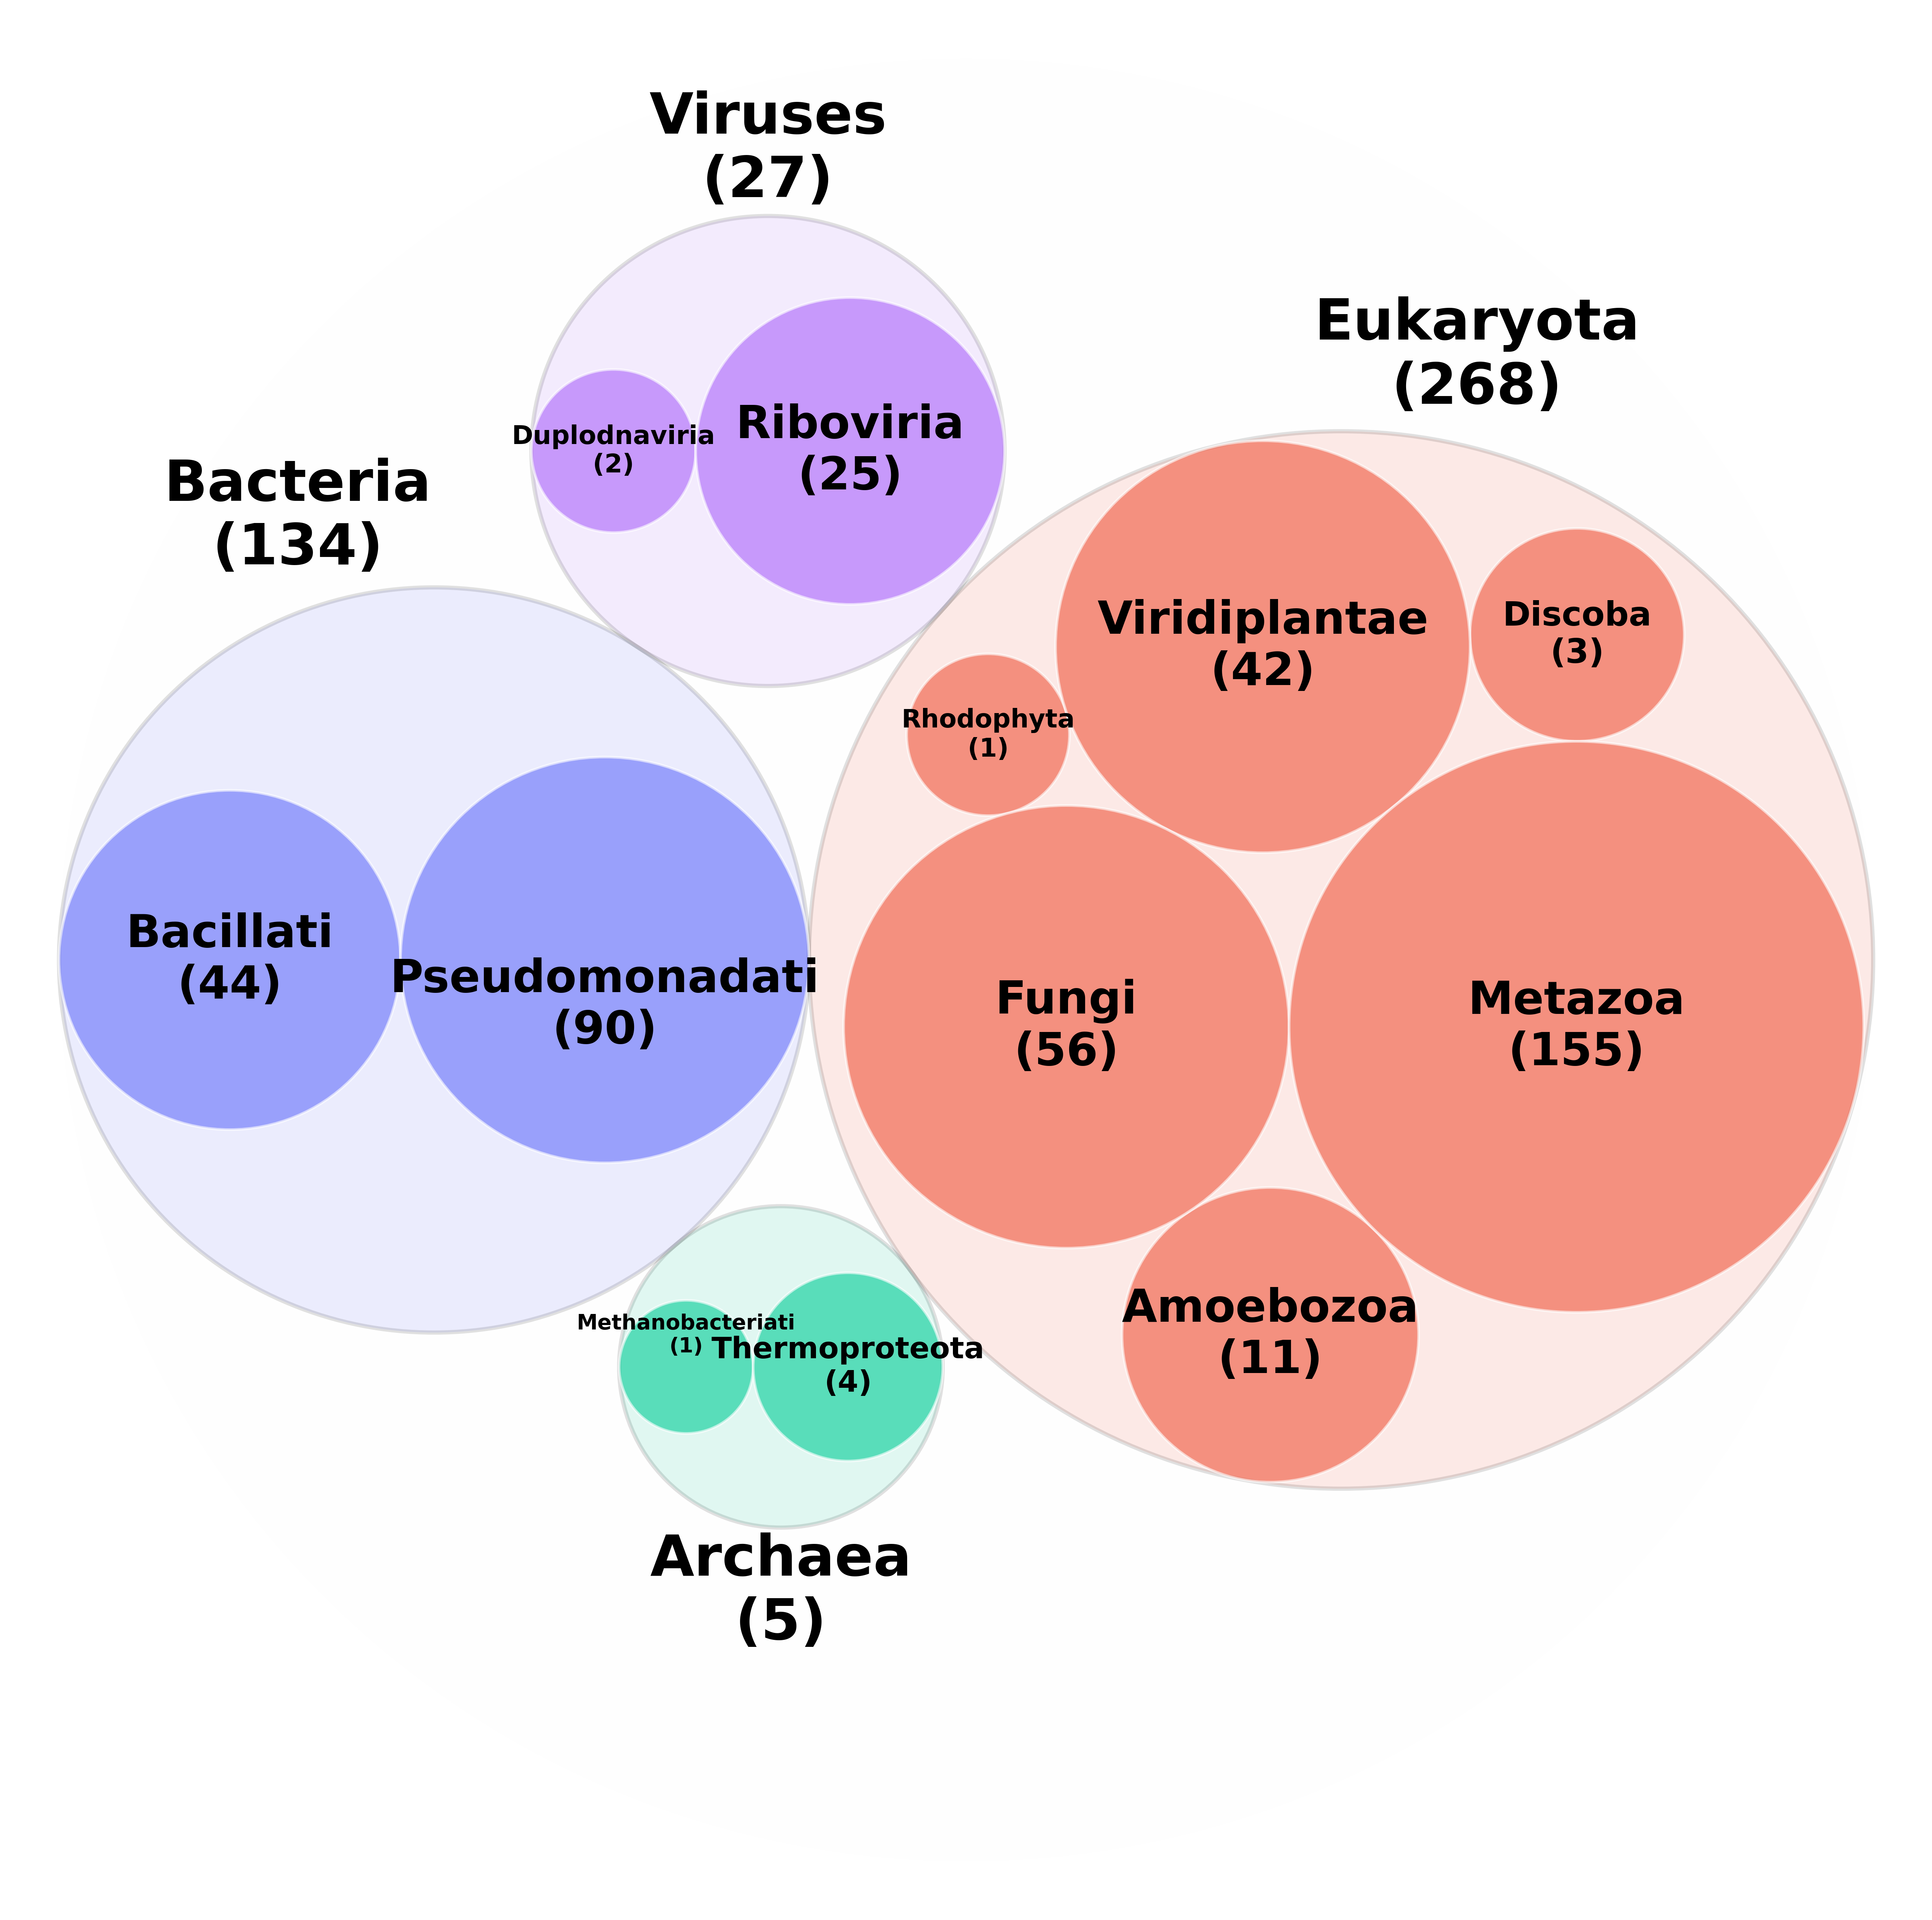


SUCCESS!

Generated files:
1. Taxonomy_CQWW.tiff
2. Domain_Phylum_Table_CQWW.csv


In [ ]:
# =========================================================
# DOMAIN + PHYLUM ONLY BUBBLE PLOT
# UNIQUE UniProt_ID COUNTS VERSION
# FINAL TIFF PUBLICATION VERSION
# =========================================================

# =========================================================
# INSTALL REQUIRED PACKAGE
# =========================================================

!pip install circlify

# =========================================================
# IMPORT LIBRARIES
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import circlify

# =========================================================
# LABEL SETTINGS
# =========================================================

LABEL_CONFIG = {

    'Domain': {
        'font_size': 30,
        'y_offset': 1.03,
        'va': 'bottom',
        'color': 'black'
    },

    'Phylum': {
        'font_size': 14,
        'y_offset': 0.0,
        'va': 'center',
        'color': 'black'
    }
}

# =========================================================
# DOMAIN LABEL POSITIONS
# =========================================================

DOMAIN_CUSTOM_POSITIONS = {

    'Bacteria': {
        'dx': -0.15,
        'dy': 1.03,
        'va': 'bottom'
    },

    'Eukaryota': {
        'dx': 0.15,
        'dy': 1.03,
        'va': 'bottom'
    },

    'Archaea': {
        'dx': 0.0,
        'dy': -1.03,
        'va': 'top'
    },

    'Viruses': {
        'dx': 0.0,
        'dy': 1.03,
        'va': 'bottom'
    }
}

# =========================================================
# DOMAIN COLORS
# =========================================================

DOMAIN_COLORS = {

    'Eukaryota': '#EF553B',

    'Bacteria': '#636EFA',

    'Viruses': '#AB63FA',

    'Archaea': '#00CC96'
}

# =========================================================
# INPUT FILE
# =========================================================

INPUT_FILE = r"CQWW_tax.csv"

# =========================================================
# LOAD DATA
# =========================================================

print(f"Reading data from {INPUT_FILE}...\n")

df = pd.read_csv(INPUT_FILE)

# =========================================================
# COLUMN NAME STANDARDIZATION
# =========================================================

df.columns = df.columns.str.strip()

# =========================================================
# KEEP ONLY DOMAIN + PHYLUM
# =========================================================

levels = [
    "Domain",
    "Phylum"
]

df[levels] = df[levels].fillna("Unclassified")

# =========================================================
# REMOVE UNKNOWN + UNCLASSIFIED TERMS
# =========================================================

remove_terms = [
    "unclassified",
    "unclassified sequence",
    "unclassified sequences",
    "unknown",
    "not_found",
    "not found",
    "nan"
]

for col in levels:

    df = df[
        ~(
            df[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(remove_terms)
        )
    ]

# =========================================================
# REMOVE UNCLASSIFIED DOMAIN ENTIRELY
# =========================================================

df = df[
    df["Domain"]
    .astype(str)
    .str.strip()
    .str.lower()
    != "unclassified"
]

# =========================================================
# REMOVE DUPLICATE UniProt IDs
# =========================================================

df = df.drop_duplicates(

    subset=[
        "uniprot_id",
        "Domain",
        "Phylum"
    ]
)

# =========================================================
# EXPORT TABLE
# =========================================================

print("Generating supplementary table...")

table_df = (
    df.groupby(levels)["uniprot_id"]
      .nunique()
      .reset_index(name='Unique_Protein_Count')
)

table_df = table_df.sort_values(

    by=['Domain', 'Unique_Protein_Count'],

    ascending=[True, False]
)

table_df.to_csv(

    "Domain_Phylum_Table.csv",

    index=False
)

# =========================================================
# BUILD 2-LEVEL HIERARCHY
# =========================================================

print("Building mathematical model...")

node_map = {}

circlify_data = []

# =========================================================
# DOMAIN LOOP
# =========================================================

for dom, d_df in df.groupby("Domain"):

    dom_children = []

    dom_scaled = 0

    # =====================================================
    # PHYLUM LOOP
    # =====================================================

    for phy, p_df in d_df.groupby("Phylum"):

        # =================================================
        # UNIQUE PROTEIN COUNTS
        # =================================================

        orig_count = p_df["uniprot_id"].nunique()

        # =================================================
        # SQRT SCALING
        # =================================================

        scaled_count = orig_count ** 0.5

        phy_id = f"{dom}|{phy}"

        node_map[phy_id] = {

            'type': 'Phylum',

            'label': phy,

            'count': orig_count,

            'domain': dom
        }

        dom_children.append({

            'id': phy_id,

            'datum': scaled_count
        })

        dom_scaled += scaled_count

    # =====================================================
    # DOMAIN NODE
    # =====================================================

    dom_id = f"{dom}"

    node_map[dom_id] = {

        'type': 'Domain',

        'label': dom,

        'count': d_df["uniprot_id"].nunique(),

        'domain': dom
    }

    circlify_data.append({

        'id': dom_id,

        'datum': dom_scaled,

        'children': dom_children
    })

# =========================================================
# GENERATE CIRCLES
# =========================================================

circles = circlify.circlify(

    circlify_data,

    show_enclosure=True,

    target_enclosure=circlify.Circle(
        x=0,
        y=0,
        r=1
    )
)

# =========================================================
# CREATE FIGURE
# =========================================================

print("Rendering figure...")

fig_plot, ax_plot = plt.subplots(

    figsize=(18, 18),

    dpi=370
)

# =========================================================
# CLEAN AXES
# =========================================================

ax_plot.axis('off')

ax_plot.set_xlim(-1.05, 1.05)

ax_plot.set_ylim(-1.05, 1.05)

fig_plot.patch.set_facecolor("white")

ax_plot.set_facecolor("white")

# =========================================================
# DRAW CIRCLES
# =========================================================

for circle in circles:

    if circle.ex is None:

        ax_plot.add_patch(

            patches.Circle(

                (circle.x, circle.y),

                circle.r,

                alpha=0.03,

                color='#E0E0E0',

                ec='none'
            )
        )

        continue

    info = node_map[circle.ex['id']]

    base_color = DOMAIN_COLORS.get(

        info['domain'],

        '#CCCCCC'
    )

    # =====================================================
    # DOMAIN STYLE
    # =====================================================

    if info['type'] == 'Domain':

        alpha = 0.12
        ec = 'black'
        lw = 2.2

    # =====================================================
    # PHYLUM STYLE
    # =====================================================

    else:

        alpha = 0.60
        ec = 'white'
        lw = 1.4

    # =====================================================
    # DRAW CIRCLE
    # =====================================================

    ax_plot.add_patch(

        patches.Circle(

            (circle.x, circle.y),

            circle.r,

            alpha=alpha,

            color=base_color,

            ec=ec,

            linewidth=lw
        )
    )

    conf = LABEL_CONFIG[info['type']]

    # =====================================================
    # DOMAIN LABELS
    # =====================================================

    if info['type'] == 'Domain':

        tweak = DOMAIN_CUSTOM_POSITIONS.get(

            info['label'],

            {
                'dx': 0.0,
                'dy': 1.03,
                'va': 'bottom'
            }
        )

        target_x = circle.x + tweak['dx']

        target_y = circle.y + (circle.r * tweak['dy'])

        label_str = (

            f"{info['label']}\n"

            f"({info['count']:,})"
        )

        ax_plot.text(

            target_x,

            target_y,

            label_str,

            ha='center',

            va=tweak['va'],

            fontsize=conf['font_size'],

            weight='bold',

            color=conf['color']
        )

    # =====================================================
    # PHYLUM LABELS
    # =====================================================

    else:

        if circle.r > 0.03:

            label_str = (

                f"{info['label']}\n"

                f"({info['count']:,})"
            )

            # =================================================
            # DYNAMIC FONT SIZE
            # =================================================

            dynamic_sz = max(
                11,
                min(
                    24,
                    circle.r * 150
                )
            )

            # =================================================
            # CUSTOM POSITION TWEAKS
            # =================================================

            x_adjust = 0
            y_adjust = 0

            # Move Orthornavirae upward
            if info['label'] == "Orthornavirae":
                y_adjust = 0.03

            # Move Thermoprotei upward
            elif info['label'] == "Thermoprotei":
                y_adjust = 0.03

            # Move Methanobacteriati upward
            elif info['label'] == "Methanobacteriati":
                y_adjust = 0.035

            # Move Pseudomonadati LOWER
            elif info['label'] == "Pseudomonadati":
                y_adjust = -0.05

            # Move Mycoplasmatota slightly right
            elif info['label'] == "Mycoplasmatota":
                x_adjust = 0.03

            # Move Viruses incertae sedis upward
            elif info['label'] == "Viruses incertae sedis":
                y_adjust = 0.05

            # =================================================
            # DRAW LABEL
            # =================================================

            ax_plot.text(

                circle.x + x_adjust,

                circle.y + y_adjust,

                label_str,

                ha='center',

                va='center',

                fontsize=dynamic_sz,

                weight='bold',

                color='black'
            )

# =========================================================
# SAVE TIFF FIGURE
# =========================================================

plt.savefig(

    "Taxonomy_CQWW.tiff",

    format="tiff",

    bbox_inches="tight",

    dpi=370,

    facecolor='white'
)

# =========================================================
# SHOW FIGURE
# =========================================================

plt.show()

# =========================================================
# DONE
# =========================================================

print("\nSUCCESS!")

print("\nGenerated files:")
print("1. Taxonomy_CQWW.tiff")
print("2. Domain_Phylum_Table_CQWW.csv")

In [ ]:
# DOMAIN + PHYLUM ONLY
# =========================================================
# INSTALL REQUIRED PACKAGES
# =========================================================
!pip install pandas matplotlib adjustText biopython numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from adjustText import adjust_text
from Bio import Entrez
import time

# =========================================================
# CONFIGURATION & SETTINGS
# =========================================================
# REQUIRED: NCBI requires an email address to use their public API
Entrez.email = "arin.heatup@gmail.com"

INPUT_FILE = "CQWW_tax.csv"
OUTPUT_FILE = "Chord_Taxonomy_Plots_Accurate.tiff"

# PLOT_STYLE: 1 = Dots and Text, 2 = Text Only
PLOT_STYLE = 1

# =========================================================
# 1. BIOPYTHON: FETCH COMPLETE PHYLA (USING TAXID SUBTREES)
# =========================================================
# Using exact NCBI TaxIDs is much more reliable than text lineage search
DOMAIN_TAX_IDS = {
    "Bacteria": "2",
    "Eukarya": "2759",    # NCBI TaxID for Eukaryota
    "Archaea": "2157",
    "Viruses": "10239"
}

def fetch_all_phyla(domain_name, tax_id):
    """Queries NCBI Taxonomy to get all officially recognized phyla for a domain."""
    query = f"txid{tax_id}[Subtree] AND phylum[Rank]"

    print(f"Fetching NCBI baseline for {domain_name} (TaxID {tax_id})...")

    try:
        # retmax bumped to 2000 to ensure we capture massive domains like Bacteria
        search_handle = Entrez.esearch(db="taxonomy", term=query, retmax=2000)
        search_results = Entrez.read(search_handle)
        search_handle.close()

        tax_ids = search_results["IdList"]
        if not tax_ids:
            return set()

        fetch_handle = Entrez.efetch(db="taxonomy", id=",".join(tax_ids), retmode="xml")
        tax_records = Entrez.read(fetch_handle)
        fetch_handle.close()

        phyla_list = [record["ScientificName"] for record in tax_records]

        # Politeness delay for NCBI servers
        time.sleep(0.5)
        return set(phyla_list) # Return as a set for safe math operations

    except Exception as e:
        print(f"Error fetching data for {domain_name}: {e}")
        return set()

# Populate the baseline reference
KNOWN_PHYLA_REFERENCE = {}

print("--- Step 1: Establishing Taxonomic Baseline ---")
for dom, tax_id in DOMAIN_TAX_IDS.items():
    KNOWN_PHYLA_REFERENCE[dom] = fetch_all_phyla(dom, tax_id)
    print(f" -> {dom}: {len(KNOWN_PHYLA_REFERENCE[dom])} total recognized phyla.")

# =========================================================
# 2. LOAD AND CLEAN CSV DATA (YOUR PEPTIDE DATA)
# =========================================================
print("\n--- Step 2: Processing Input Dataset ---")
try:
    df = pd.read_csv(INPUT_FILE)
    df.columns = df.columns.str.strip()

    # Standardize terminology based on supervisor's request
    df["Domain"] = df["Domain"].replace({"Eukaryota": "Eukarya"})

    # Remove unclassified or missing data
    df = df.dropna(subset=["Domain", "Phylum"])
    remove_terms = ["unclassified", "unknown", "nan", "not found", "unclassified sequences"]
    df = df[~df["Domain"].astype(str).str.lower().isin(remove_terms)]
    df = df[~df["Phylum"].astype(str).str.lower().isin(remove_terms)]

    # Group by domain to find unique present phyla
    present_phyla = df.groupby("Domain")["Phylum"].unique().apply(set).to_dict()

except FileNotFoundError:
    print(f"Error: {INPUT_FILE} not found. Cannot proceed.")
    exit()

# =========================================================
# 3. PLOTTING SETUP & GEOMETRY
# =========================================================
print("\n--- Step 3: Rendering Figure ---")
fig, axes = plt.subplots(2, 2, figsize=(24, 24), dpi=300)
axes = axes.flatten()
fig.patch.set_facecolor('white')

colors = {"Bacteria": "#636EFA", "Eukarya": "#EF553B", "Archaea": "#00CC96", "Viruses": "#AB63FA"}
domains_to_plot = ["Bacteria", "Eukarya", "Archaea", "Viruses"]

def get_random_points_in_semicircle(n, is_left=True, radius=0.9):
    """Generates random coordinates strictly inside a left or right semicircle."""
    points = []
    for _ in range(n):
        # Distribute closer to the center to give text room on the edges
        r = np.random.uniform(0.1, radius * 0.8)
        if is_left:
            theta = np.random.uniform(np.pi/2 + 0.15, 3*np.pi/2 - 0.15)
        else:
            theta = np.random.uniform(-np.pi/2 + 0.15, np.pi/2 - 0.15)
        points.append((r * np.cos(theta), r * np.sin(theta)))
    return points

# =========================================================
# 4. DRAW THE MATRIX
# =========================================================
for idx, domain in enumerate(domains_to_plot):
    ax = axes[idx]
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)

    # Base Domain Circle & Chord
    circle = patches.Circle((0, 0), 1, alpha=0.08, color=colors[domain], ec='black', lw=1.5)
    ax.add_patch(circle)
    ax.plot([0, 0], [-1, 1], color='black', lw=2, linestyle='--')

    # Shade the Absent (X-Y) side grayish
    left_semicircle = patches.Wedge((0, 0), 1, 90, 270, alpha=0.15, color='gray')
    ax.add_patch(left_semicircle)

    # Domain Title
    ax.text(0, 1.05, domain, ha='center', va='bottom', fontsize=26, weight='bold', color=colors.get(domain, 'black'))

    # Mathematical Subtraction (Total X - Present Y) safely cast as sets to prevent AttributeErrors
    Y_phyla = present_phyla.get(domain, set())
    X_phyla = KNOWN_PHYLA_REFERENCE.get(domain, set())

    all_phyla = set(X_phyla).union(set(Y_phyla))
    absent_phyla = list(all_phyla - set(Y_phyla))
    Y_phyla_list = list(Y_phyla)

    # Sub-labels
    ax.text(-0.5, -1.05, f"Absent Phyla ({len(absent_phyla)})", ha='center', fontsize=14, color='gray', weight='bold')
    ax.text(0.5, -1.05, f"Present Phyla ({len(Y_phyla_list)})", ha='center', fontsize=14, color='black', weight='bold')

    texts = []

    # Plot Absent Phyla (Left Side)
    # Scale font size down if there are hundreds of phyla to prevent text collision failure
    absent_font_size = 8 if len(absent_phyla) > 30 else 10

    left_coords = get_random_points_in_semicircle(len(absent_phyla), is_left=True)
    for i, p_name in enumerate(absent_phyla):
        x, y = left_coords[i]
        if PLOT_STYLE == 1:
            ax.plot(x, y, 'o', color='gray', markersize=4, alpha=0.4)
        texts.append(ax.text(x, y, p_name, fontsize=absent_font_size, color='#505050', alpha=0.8))

    # Plot Present Phyla (Right Side)
    right_coords = get_random_points_in_semicircle(len(Y_phyla_list), is_left=False)
    for i, p_name in enumerate(Y_phyla_list):
        x, y = right_coords[i]
        if PLOT_STYLE == 1:
            ax.plot(x, y, 'o', color=colors[domain], markersize=10, alpha=0.9)
        texts.append(ax.text(x, y, p_name, fontsize=12, weight='bold', color='black'))

    # Apply Anti-Collision Algorithm
    if texts:
        print(f" -> Resolving text collisions for {domain} ({len(texts)} labels)...")
        adjust_text(texts, ax=ax,
                    force_points=0.2,
                    force_text=0.3,
                    expand_points=(1.2, 1.2),
                    expand_text=(1.1, 1.1))

# =========================================================
# 5. SAVE AND EXPORT
# =========================================================
plt.tight_layout()
plt.savefig(OUTPUT_FILE, format="tiff", bbox_inches="tight", dpi=300)
print(f"\n✅ SUCCESS! Scientifically accurate plot saved as {OUTPUT_FILE}")
plt.show()

--- Step 1: Establishing Taxonomic Baseline ---
Fetching NCBI baseline for Bacteria (TaxID 2)...
 -> Bacteria: 192 total recognized phyla.
Fetching NCBI baseline for Eukarya (TaxID 2759)...
 -> Eukarya: 79 total recognized phyla.
Fetching NCBI baseline for Archaea (TaxID 2157)...
 -> Archaea: 45 total recognized phyla.
Fetching NCBI baseline for Viruses (TaxID 10239)...
 -> Viruses: 22 total recognized phyla.

--- Step 2: Processing Input Dataset ---

--- Step 3: Rendering Figure ---
 -> Resolving text collisions for Bacteria (194 labels)...
 -> Resolving text collisions for Eukarya (84 labels)...
 -> Resolving text collisions for Archaea (46 labels)...
 -> Resolving text collisions for Viruses (24 labels)...

✅ SUCCESS! Scientifically accurate plot saved as Chord_Taxonomy_Plots_Accurate.tiff


In [ ]:
# adding GO information

import pandas as pd
import requests
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
import time

# =========================================
# CONFIG
# =========================================
INPUT_FILE = "CQWW_tax.csv"

OUTPUT_FILE = "CQWW_GO.csv"

CHECKPOINT_FILE = "go_checkpoint.csv"

BASE_URL = "https://rest.uniprot.org/uniprotkb/"

MAX_WORKERS = 4
MAX_RETRIES = 5

# =========================================
# CHUNK SETTINGS
# =========================================
CHUNKSIZE = 100000

# =========================================
# REQUEST SESSION
# =========================================
session = requests.Session()

# =========================================
# LOAD OLD CHECKPOINT
# =========================================
results_dict = {}

if os.path.exists(CHECKPOINT_FILE):

    print("\nLoading previous checkpoint...")

    old_df = pd.read_csv(
        CHECKPOINT_FILE,
        low_memory=False
    )

    for row in old_df.itertuples():

        results_dict[row.uniprot_id] = (
            row.GO_Biological_Process,
            row.GO_Molecular_Function,
            row.GO_Cellular_Component
        )

    print(
        f"Recovered {len(results_dict)} completed IDs"
    )

# =========================================
# FETCH FUNCTION
# =========================================
def fetch_go(uid):

    url = BASE_URL + uid + ".json"

    for attempt in range(MAX_RETRIES):

        try:

            r = session.get(
                url,
                timeout=20
            )

            if r.status_code != 200:

                time.sleep(1)
                continue

            data = r.json()

            process_terms = []
            function_terms = []
            component_terms = []

            # =================================
            # EXTRACT GO TERMS
            # =================================
            for xref in data.get(
                "uniProtKBCrossReferences",
                []
            ):

                if xref.get("database") == "GO":

                    for p in xref.get(
                        "properties",
                        []
                    ):

                        if p.get("key") == "GoTerm":

                            term = p.get("value")

                            if term.startswith("P:"):

                                process_terms.append(
                                    term[2:]
                                )

                            elif term.startswith("F:"):

                                function_terms.append(
                                    term[2:]
                                )

                            elif term.startswith("C:"):

                                component_terms.append(
                                    term[2:]
                                )

            return uid, (
                "; ".join(process_terms),
                "; ".join(function_terms),
                "; ".join(component_terms),
                True
            )

        except Exception as e:

            print(
                f"Retry {attempt+1} "
                f"for {uid}: {e}"
            )

            time.sleep(
                2 * (attempt + 1)
            )

    # =====================================
    # FAILED AFTER RETRIES
    # =====================================
    return uid, (
        None,
        None,
        None,
        False
    )

# =========================================
# COUNT TOTAL ROWS
# =========================================
print("\nCounting total rows...")

total_rows = (
    sum(1 for _ in open(INPUT_FILE)) - 1
)

total_chunks = (
    total_rows // CHUNKSIZE
) + 1

print(f"Total rows: {total_rows:,}")
print(f"Total chunks: {total_chunks:,}")

# =========================================
# OUTPUT HEADER FLAG
# =========================================
first_write = True

# =========================================
# SUMMARY COUNTS
# =========================================
total_success = 0
total_fail = 0

# =========================================
# PROCESS INPUT FILE IN CHUNKS
# =========================================
for chunk in tqdm(
    pd.read_csv(
        INPUT_FILE,
        chunksize=CHUNKSIZE,
        low_memory=False
    ),
    total=total_chunks,
    desc="Processing Chunks"
):

    # =====================================
    # CLEAN IDS
    # =====================================
    chunk["uniprot_id"] = (
        chunk["uniprot_id"]
        .astype(str)
        .str.strip()
    )

    # =====================================
    # UNIQUE IDS IN CHUNK
    # =====================================
    unique_ids = (
        chunk["uniprot_id"]
        .dropna()
        .unique()
        .tolist()
    )

    # =====================================
    # FIND REMAINING IDS
    # =====================================
    remaining_ids = [
        uid
        for uid in unique_ids
        if uid not in results_dict
    ]

    print(
        f"\nChunk rows: {len(chunk):,}"
    )

    print(
        f"Unique IDs in chunk: "
        f"{len(unique_ids):,}"
    )

    print(
        f"New IDs to fetch: "
        f"{len(remaining_ids):,}"
    )

    # =====================================
    # PARALLEL FETCH
    # =====================================
    new_rows = []

    with ThreadPoolExecutor(
        max_workers=MAX_WORKERS
    ) as executor:

        futures = [
            executor.submit(
                fetch_go,
                uid
            )
            for uid in remaining_ids
        ]

        for f in tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Fetching GO",
            leave=False
        ):

            uid, result = f.result()

            bp, mf, cc, success = result

            if success:

                results_dict[uid] = (
                    bp,
                    mf,
                    cc
                )

                total_success += 1

                checkpoint_row = {
                    "uniprot_id": uid,
                    "GO_Biological_Process": bp,
                    "GO_Molecular_Function": mf,
                    "GO_Cellular_Component": cc
                }

                new_rows.append(
                    checkpoint_row
                )

            else:

                total_fail += 1

    # =====================================
    # SAVE CHECKPOINT
    # =====================================
    if len(new_rows) > 0:

        checkpoint_df = pd.DataFrame(
            new_rows
        )

        if os.path.exists(
            CHECKPOINT_FILE
        ):

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                mode="a",
                header=False,
                index=False
            )

        else:

            checkpoint_df.to_csv(
                CHECKPOINT_FILE,
                index=False
            )

    # =====================================
    # MAP GO TERMS TO CURRENT CHUNK
    # =====================================
    chunk["GO_Biological_Process"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[0]
        )
    )

    chunk["GO_Molecular_Function"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[1]
        )
    )

    chunk["GO_Cellular_Component"] = (
        chunk["uniprot_id"]
        .map(
            lambda x:
            results_dict.get(
                x,
                (None, None, None)
            )[2]
        )
    )

    # =====================================
    # SAVE CHUNK OUTPUT
    # =====================================
    if first_write:

        chunk.to_csv(
            OUTPUT_FILE,
            index=False,
            mode="w"
        )

        first_write = False

    else:

        chunk.to_csv(
            OUTPUT_FILE,
            index=False,
            mode="a",
            header=False
        )

    print(
        f"Chunk saved to "
        f"{OUTPUT_FILE}"
    )

# =========================================
# FINAL SUMMARY
# =========================================
print("\n==============================")
print("GO ANNOTATION COMPLETE")
print("==============================")
print(
    f"\nSuccessful IDs: "
    f"{total_success}"
)
print(
    f"Failed IDs: "
    f"{total_fail}"
)
print(
    f"\nCheckpoint saved:"
)
print(CHECKPOINT_FILE)
print(
    f"\nFinal output:"
)
print(OUTPUT_FILE)


Counting total rows...
Total rows: 440
Total chunks: 1


Processing Chunks:   0%|          | 0/1 [00:00<?, ?it/s]


Chunk rows: 440
Unique IDs in chunk: 440
New IDs to fetch: 440



Processing Chunks: 100%|██████████| 1/1 [04:19<00:00, 259.72s/it]

Chunk saved to CQWW_GO.csv

GO ANNOTATION COMPLETE

Successful IDs: 440
Failed IDs: 0

Checkpoint saved:
go_checkpoint.csv

Final output:
CQWW_GO.csv


Reading file in chunks...
Finished processing.


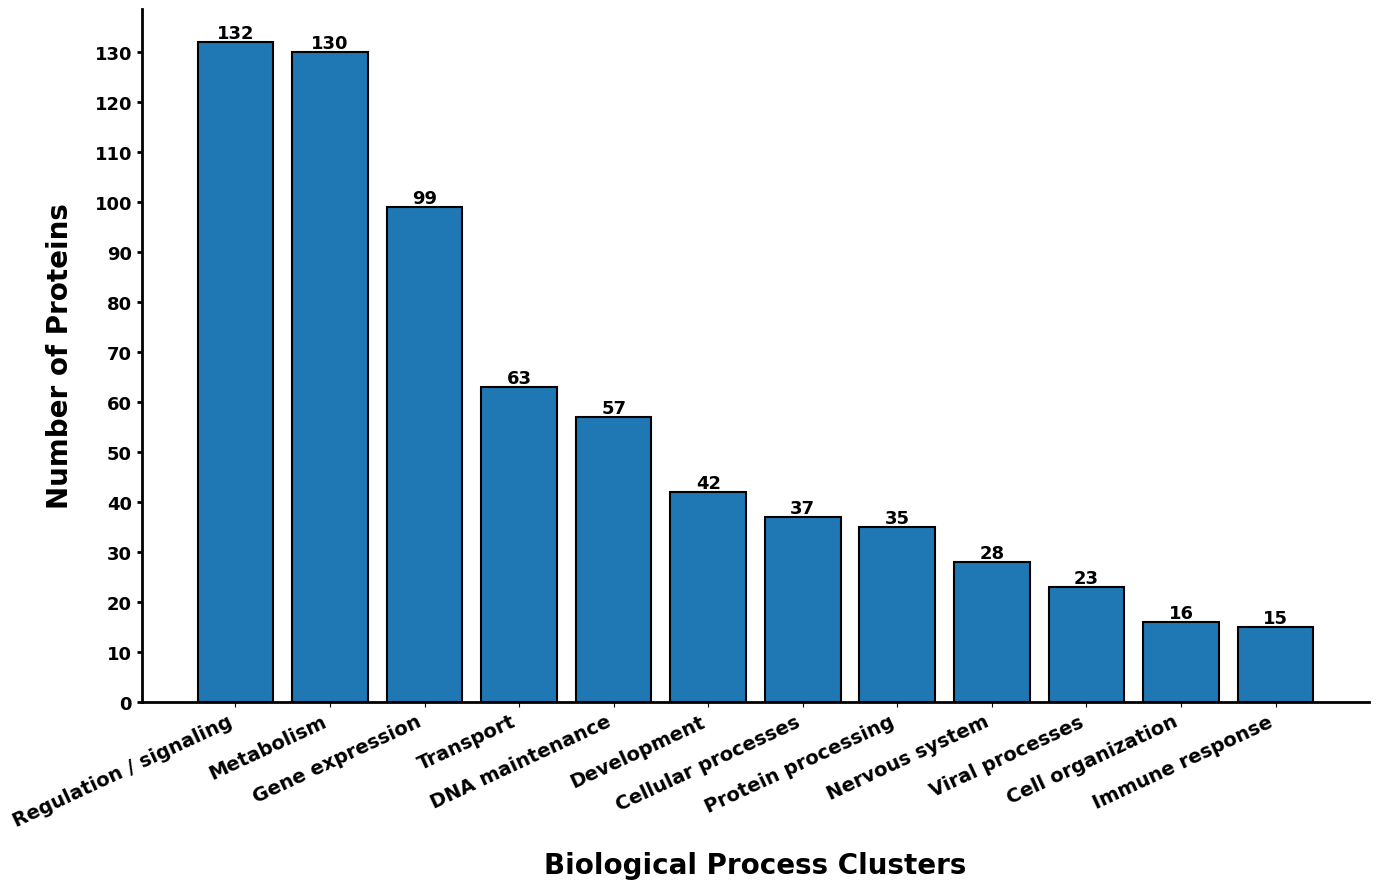

Figure saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# =========================================================
# SETTINGS
# =========================================================

FILE_PATH = r"CQWW_GO.csv"

CHUNK_SIZE = 10000

TOP_N = 15

# =========================================================
# DEFINE BIOLOGICAL PROCESS CLUSTERS
# =========================================================

bp_clusters = {

    "Viral processes": [
        "viral", "symbiont", "virion"
    ],

    "Gene expression": [
        "transcription", "translation",
        "ribosome", "mirna", "rna",
        "preribosome"
    ],

    "DNA maintenance": [
        "dna", "recombination",
        "replication", "repair"
    ],

    "Metabolism": [
        "metabolic", "biosynthetic",
        "respiration", "glycolytic",
        "catabolic", "glucose",
        "fatty acid"
    ],

    "Cellular processes": [
        "cell cycle", "cell division",
        "proliferation", "endocytosis",
        "differentiation"
    ],

    "Transport": [
        "transport", "secretion",
        "localization", "import",
        "translocation"
    ],

    "Nervous system": [
        "neuron", "axon",
        "synapse", "brain",
        "memory"
    ],

    "Regulation / signaling": [
        "signal", "regulation",
        "response", "phosphorylation",
        "chromatin"
    ],

    "Protein processing": [
        "proteolysis",
        "ubiquitin",
        "folding"
    ],

    "Cell organization": [
        "cytoskeleton",
        "organelle",
        "adhesion"
    ],

    "Immune response": [
        "defense",
        "apoptotic",
        "degranulation"
    ],

    "Development": [
        "development",
        "morphogenesis",
        "germination"
    ]
}

# =========================================================
# STORE:
# Cluster -> unique proteins
# =========================================================

cluster_to_proteins = defaultdict(set)

# =========================================================
# READ FILE IN CHUNKS
# =========================================================

print("Reading file in chunks...")

for chunk in pd.read_csv(FILE_PATH, chunksize=CHUNK_SIZE):

    # Keep required columns
    chunk = chunk[["uniprot_id", "GO_Biological_Process"]]

    # Remove missing GO entries
    chunk = chunk.dropna(subset=["GO_Biological_Process"])

    # =====================================================
    # PROCESS ROWS
    # =====================================================

    for _, row in chunk.iterrows():

        protein = row["uniprot_id"]

        bp_entry = row["GO_Biological_Process"]

        # Split GO terms
        terms = str(bp_entry).split(";")

        for term in terms:

            term_lower = term.lower().strip()

            # Match clusters
            for cluster, keywords in bp_clusters.items():

                if any(keyword in term_lower for keyword in keywords):

                    cluster_to_proteins[cluster].add(protein)

print("Finished processing.")

# =========================================================
# COUNT UNIQUE PROTEINS
# =========================================================

cluster_counts = {
    cluster: len(proteins)
    for cluster, proteins in cluster_to_proteins.items()
}

# =========================================================
# CREATE DATAFRAME
# =========================================================

plot_df = pd.DataFrame(
    cluster_counts.items(),
    columns=["Biological Process Cluster", "Protein Count"]
)

# Sort
plot_df = plot_df.sort_values(
    by="Protein Count",
    ascending=False
).head(TOP_N)

# =========================================================
# PLOT
# =========================================================

fig, ax = plt.subplots(figsize=(14, 9))

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# =========================================================
# VERTICAL BARS
# =========================================================

bars = ax.bar(
    plot_df["Biological Process Cluster"],
    plot_df["Protein Count"],
    edgecolor="black",
    linewidth=1.5,
    width=0.8
)

# =========================================================
# VALUE LABELS
# =========================================================

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height):,}",
        ha='center',
        va='bottom',
        fontsize=13,
        fontweight='bold'
    )

# =========================================================
# AXIS LABELS
# =========================================================

ax.set_xlabel(
    "Biological Process Clusters",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

ax.set_ylabel(
    "Number of Proteins",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

# =========================================================
# CUSTOM Y-AXIS (GAP OF 10)
# =========================================================

from matplotlib.ticker import MultipleLocator

# Y-axis tick gap = 10
ax.yaxis.set_major_locator(MultipleLocator(10))

# Tick styling
ax.tick_params(
    axis='y',
    labelsize=13,
    width=2
)

# Make y-axis labels bold
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

# =========================================================
# X-TICKS
# =========================================================

plt.xticks(
    rotation=25,
    ha='right',
    fontsize=14,
    fontweight='bold'
)


# =========================================================
# SPINES
# =========================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout()

# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "Clustered_GO_Biological_Processes_CQWW.tiff",
    dpi=370,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved successfully.")

Reading file in chunks...
Finished processing.


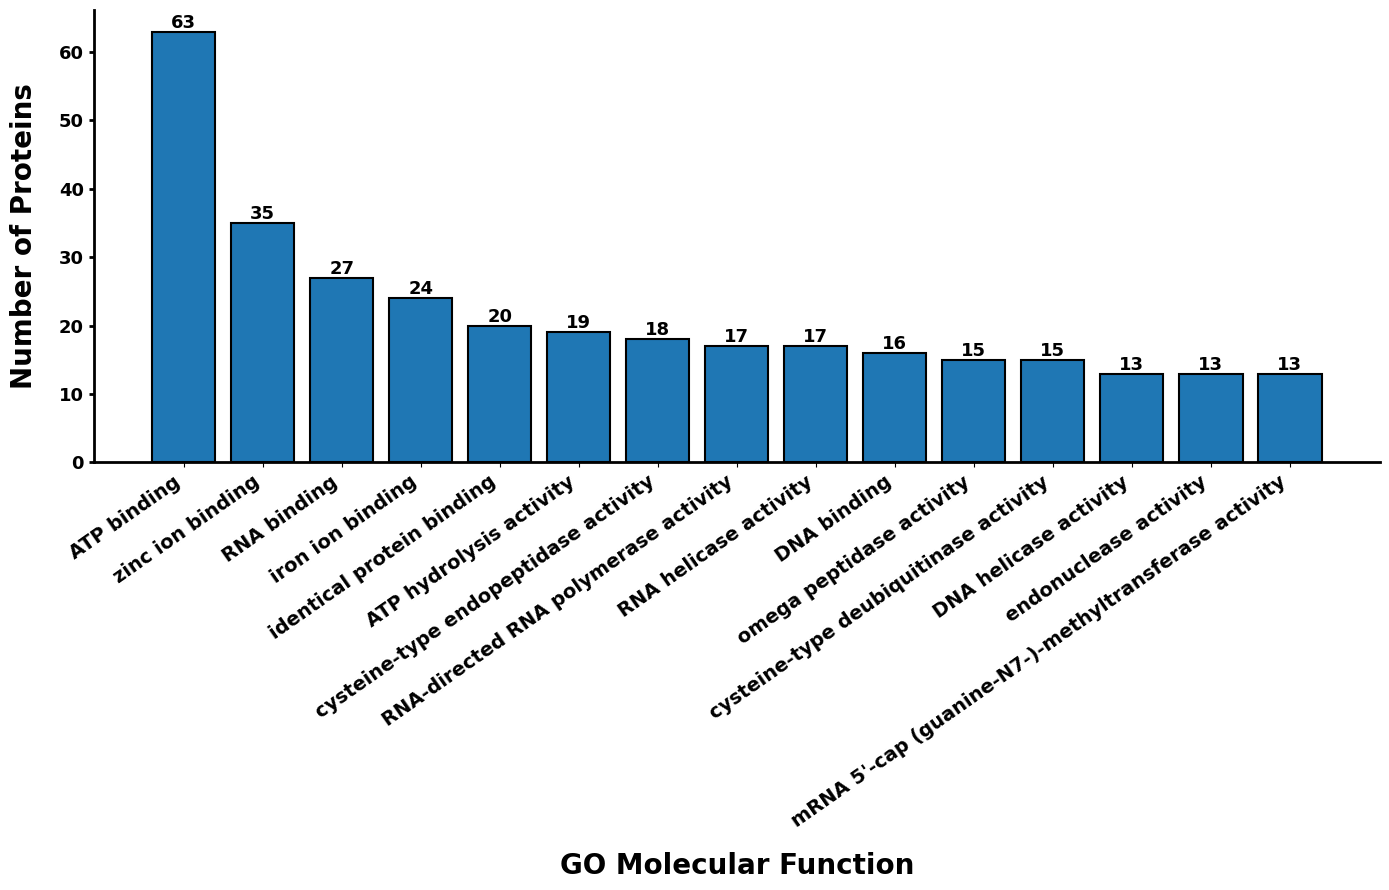

Figure saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# =========================================================
# SETTINGS
# =========================================================

FILE_PATH = r"CQWW_GO.csv"

CHUNK_SIZE = 10000

GO_COLUMN = "GO_Molecular_Function"

TOP_N = 15

# =========================================================
# STORE:
# GO term -> unique proteins
# =========================================================

go_to_proteins = defaultdict(set)

# =========================================================
# READ FILE IN CHUNKS
# =========================================================

print("Reading file in chunks...")

for chunk in pd.read_csv(FILE_PATH, chunksize=CHUNK_SIZE):

    # Keep only required columns
    chunk = chunk[["uniprot_id", GO_COLUMN]]

    # Remove rows with missing GO annotations
    chunk = chunk.dropna(subset=[GO_COLUMN])

    # =====================================================
    # PROCESS ROWS
    # =====================================================

    for _, row in chunk.iterrows():

        protein = row["uniprot_id"]

        go_entry = row[GO_COLUMN]

        # Split GO terms
        terms = str(go_entry).split(";")

        for term in terms:

            term = term.strip()

            if term:
                go_to_proteins[term].add(protein)

print("Finished processing.")

# =========================================================
# COUNT UNIQUE PROTEINS
# =========================================================

go_counts = {
    term: len(proteins)
    for term, proteins in go_to_proteins.items()
}

# =========================================================
# CREATE DATAFRAME
# =========================================================

plot_df = pd.DataFrame(
    go_counts.items(),
    columns=["GO Term", "Protein Count"]
)

# Sort and select top terms
plot_df = plot_df.sort_values(
    by="Protein Count",
    ascending=False
).head(TOP_N)

# =========================================================
# PLOT
# =========================================================

fig, ax = plt.subplots(figsize=(14, 9))

# White background
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# =========================================================
# VERTICAL BARS
# =========================================================

bars = ax.bar(
    plot_df["GO Term"],
    plot_df["Protein Count"],
    edgecolor="black",
    linewidth=1.5,
    width=0.8
)

# =========================================================
# VALUE LABELS
# =========================================================

for bar in bars:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height):,}",
        ha='center',
        va='bottom',
        fontsize=13,
        fontweight='bold'
    )

# =========================================================
# AXIS LABELS
# =========================================================

ax.set_xlabel(
    "GO Molecular Function",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

ax.set_ylabel(
    "Number of Proteins",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

# =========================================================
# AUTOMATIC Y-AXIS
# =========================================================

# Let matplotlib decide y-axis automatically
ax.tick_params(
    axis='y',
    labelsize=13,
    width=2
)

# Make y-axis labels bold
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

# =========================================================
# X-TICKS
# =========================================================

plt.xticks(
    rotation=35,
    ha='right',
    fontsize=14,
    fontweight='bold'
)

# =========================================================
# SPINES
# =========================================================

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Thicker axes
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

# =========================================================
# LAYOUT
# =========================================================

plt.tight_layout()

# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(
    "Top_GO_Molecular_Functions_CQWW.tiff",
    dpi=370,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved successfully.")

In [ ]:
# ============================================================
# GOOGLE COLAB CODE
# Ambush Hypothesis Analysis for 12-mers
#
# This code:
# 1. Reads CDS sequences from CSV
# 2. Uses Biopython translation tables
# 3. Checks stop codons in:
#       original frame
#       +1 shifted frame
#       +2 shifted frame
# 4. Counts mapped 12mers for +1 and +2 shifts
# 5. Finds stop codons before the first mapped 12mer
# 6. Finds stop codons inside mapped 12mers
# 7. Performs paired t-test + Bonferroni correction
# 8. Saves detailed results, summary files, and inferential statistics
# ============================================================

# ============================================================
# INSTALL DEPENDENCIES
# ============================================================

!pip install biopython statsmodels -q

# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
from tqdm import tqdm
from collections import defaultdict
from Bio.Data import CodonTable
import re

from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from itertools import combinations

# ============================================================
# FILE PATHS
# ============================================================

input_file = "CQWW_frames.csv"

output_file = "ambush_hypothesis_results_with_first12mer.csv"
summary_output_file = "ambush_hypothesis_summary_with_first12mer.csv"

mapped12mer_output_file = "mapped12mer_stopcodon_analysis.csv"
mapped12mer_summary_file = "mapped12mer_stopcodon_summary.csv"

inferential_output_file = "stop_count_ttest_bonferroni_results_12mer.csv"

# ============================================================
# CLEAN FUNCTIONS
# ============================================================

def clean_sequence(seq):
    seq = str(seq).upper()
    seq = seq.replace("U", "T")
    seq = re.sub(r"[^ATGC]", "", seq)
    return seq


def normalize_shift(x):
    x = str(x).strip()

    if x in ["1", "1.0"]:
        return "1"

    if x in ["2", "2.0"]:
        return "2"

    if x in ["transl_table_issue", "trans_table_issue"]:
        return "transl_table_issue"

    return x


def normalize_transl_table(x):
    try:
        return int(float(str(x).strip()))
    except Exception:
        return None


def clean_position_plus_one(pos):
    try:
        pos = str(pos).strip()

        if "|" in pos:
            pos = pos.split("|")[0]

        return int(float(pos)) + 1

    except Exception:
        return None


def get_shifted_codons(seq, shift):
    shifted_seq = seq[shift:]
    codons = []

    for i in range(0, len(shifted_seq) - 2, 3):
        codon = shifted_seq[i:i + 3]

        if len(codon) == 3:
            codons.append(codon)

    return codons


def find_stop_codons(codons, stop_codons):
    stop_positions = []
    stop_codon_list = []

    for idx, codon in enumerate(codons):
        if codon in stop_codons:
            stop_positions.append(idx + 1)
            stop_codon_list.append(codon)

    return stop_codon_list, stop_positions


def count_stop_codons_before_nt_position(seq, frame_shift, stop_codons, nt_position):
    """
    Counts stop codons before the first mapped 12mer.

    nt_position is 1-based nucleotide position.
    frame_shift:
        0 = original frame
        1 = +1 frame
        2 = +2 frame
    """

    if nt_position is None or pd.isna(nt_position):
        return 0, "", ""

    codons = get_shifted_codons(seq, frame_shift)

    stop_count = 0
    stop_codon_list = []
    stop_position_list = []

    for idx, codon in enumerate(codons):
        codon_start_0based = frame_shift + idx * 3
        codon_start_1based = codon_start_0based + 1

        if codon_start_1based >= nt_position:
            break

        if codon in stop_codons:
            stop_count += 1
            stop_codon_list.append(codon)
            stop_position_list.append(idx + 1)

    return (
        stop_count,
        "|".join(stop_codon_list),
        "|".join(map(str, stop_position_list))
    )


def count_stop_codons_inside_12mer_all_frames(seq12, stop_codons):
    """
    Counts stop codons inside a 12mer across internal frames 0, 1, and 2.
    """

    seq12 = clean_sequence(seq12)

    stop_count = 0
    found_stop_codons = []
    found_internal_frames = []
    found_positions = []

    for frame in [0, 1, 2]:
        codons = get_shifted_codons(seq12, frame)

        for idx, codon in enumerate(codons):
            if codon in stop_codons:
                stop_count += 1
                found_stop_codons.append(codon)
                found_internal_frames.append(str(frame))
                found_positions.append(str(idx + 1))

    return (
        stop_count,
        "|".join(found_stop_codons),
        "|".join(found_internal_frames),
        "|".join(found_positions)
    )


# ============================================================
# LOAD DATA
# ============================================================

print("\nLoading dataset...")

df = pd.read_csv(
    input_file,
    dtype=str,
    low_memory=False
)

print("\nDataset loaded.")
print("Total rows:", len(df))

# ============================================================
# CLEAN DATA
# ============================================================

print("\nCleaning dataset...")

df["shift"] = df["shift"].apply(normalize_shift)
df["cds_sequence_clean"] = df["cds_sequence"].apply(clean_sequence)

# IMPORTANT: this assumes your tetrapeptide file has a column named matched_12mer
df["matched_12mer_clean"] = df["matched_12mer"].apply(clean_sequence)

df["transl_table_clean"] = df["transl_table"].apply(normalize_transl_table)
df["position_corrected_plus_one"] = df["positions"].apply(clean_position_plus_one)

print("\nShift distribution:")
print(df["shift"].value_counts(dropna=False))

print("\nTranslation table distribution:")
print(df["transl_table_clean"].value_counts(dropna=False))

# ============================================================
# BUILD UNIQUE CDS TABLE
# ============================================================

print("\nBuilding unique CDS table...")

unique_cds = df[
    ["cds_sequence_clean", "transl_table_clean"]
].drop_duplicates()

unique_cds = unique_cds.dropna(
    subset=["transl_table_clean"]
)

unique_cds["transl_table_clean"] = unique_cds[
    "transl_table_clean"
].astype(int)

print(
    "Unique CDS + translation table combinations:",
    len(unique_cds)
)

# ============================================================
# COUNT MAPPED 12MERS AND FIRST MAPPED 12MER POSITION
# ============================================================

print("\nCounting mapped 12mers and first mapped 12mer position...")

shift1_counts = defaultdict(int)
shift2_counts = defaultdict(int)
transl_table_issue_counts = defaultdict(int)
all_mapped_counts = defaultdict(int)

first_mapped_position = {}

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Counting mapped 12mers"
):

    cds = row["cds_sequence_clean"]
    shift = row["shift"]
    pos = row["position_corrected_plus_one"]

    if shift == "1":
        shift1_counts[cds] += 1
        all_mapped_counts[cds] += 1

    elif shift == "2":
        shift2_counts[cds] += 1
        all_mapped_counts[cds] += 1

    elif shift == "transl_table_issue":
        transl_table_issue_counts[cds] += 1
        all_mapped_counts[cds] += 1

    if pos is not None and not pd.isna(pos):
        if cds not in first_mapped_position:
            first_mapped_position[cds] = pos
        else:
            first_mapped_position[cds] = min(
                first_mapped_position[cds],
                pos
            )

# ============================================================
# MAIN CDS-LEVEL AMBUSH ANALYSIS
# ============================================================

print(
    "\nRunning original-frame, +1-frame, +2-frame, "
    "and before-first-12mer stop codon analysis..."
)

results = []
invalid_translation_tables = []

for _, row in tqdm(
    unique_cds.iterrows(),
    total=len(unique_cds),
    desc="CDS-level stop codon analysis"
):

    cds_seq = row["cds_sequence_clean"]
    transl_table_id = row["transl_table_clean"]

    try:
        codon_table = CodonTable.unambiguous_dna_by_id[
            transl_table_id
        ]

        stop_codons = set(codon_table.stop_codons)

    except Exception:
        invalid_translation_tables.append(transl_table_id)
        continue

    # Original frame
    original_codons = get_shifted_codons(cds_seq, 0)
    original_stop_codons, original_stop_positions = find_stop_codons(
        original_codons,
        stop_codons
    )

    # +1 frame
    plus1_codons = get_shifted_codons(cds_seq, 1)
    plus1_stop_codons, plus1_stop_positions = find_stop_codons(
        plus1_codons,
        stop_codons
    )

    # +2 frame
    plus2_codons = get_shifted_codons(cds_seq, 2)
    plus2_stop_codons, plus2_stop_positions = find_stop_codons(
        plus2_codons,
        stop_codons
    )

    # Stop codons before first mapped 12mer
    first_pos = first_mapped_position.get(cds_seq, np.nan)

    original_before_count, original_before_codons, original_before_positions = (
        count_stop_codons_before_nt_position(
            cds_seq,
            0,
            stop_codons,
            first_pos
        )
    )

    plus1_before_count, plus1_before_codons, plus1_before_positions = (
        count_stop_codons_before_nt_position(
            cds_seq,
            1,
            stop_codons,
            first_pos
        )
    )

    plus2_before_count, plus2_before_codons, plus2_before_positions = (
        count_stop_codons_before_nt_position(
            cds_seq,
            2,
            stop_codons,
            first_pos
        )
    )

    results.append({

        "cds_sequence": cds_seq,
        "translation_table": transl_table_id,
        "stop_codons_for_table": "|".join(sorted(stop_codons)),
        "cds_length_nt": len(cds_seq),
        "first_mapped_12mer_nt_position": first_pos,

        # Original frame
        "original_total_codons": len(original_codons),
        "original_stop_count": len(original_stop_codons),
        "original_stop_density_per_100_codons": (
            len(original_stop_codons) / len(original_codons) * 100
        ) if len(original_codons) > 0 else np.nan,
        "original_stop_codons": "|".join(original_stop_codons),
        "original_stop_positions": "|".join(map(str, original_stop_positions)),

        # +1 frame
        "plus1_total_codons": len(plus1_codons),
        "plus1_stop_count": len(plus1_stop_codons),
        "plus1_stop_density_per_100_codons": (
            len(plus1_stop_codons) / len(plus1_codons) * 100
        ) if len(plus1_codons) > 0 else np.nan,
        "plus1_stop_codons": "|".join(plus1_stop_codons),
        "plus1_stop_positions": "|".join(map(str, plus1_stop_positions)),
        "plus1_mapped_12mers": shift1_counts.get(cds_seq, 0),

        # +2 frame
        "plus2_total_codons": len(plus2_codons),
        "plus2_stop_count": len(plus2_stop_codons),
        "plus2_stop_density_per_100_codons": (
            len(plus2_stop_codons) / len(plus2_codons) * 100
        ) if len(plus2_codons) > 0 else np.nan,
        "plus2_stop_codons": "|".join(plus2_stop_codons),
        "plus2_stop_positions": "|".join(map(str, plus2_stop_positions)),
        "plus2_mapped_12mers": shift2_counts.get(cds_seq, 0),

        # Mapped 12mer summary
        "transl_table_issue_mapped_12mers": transl_table_issue_counts.get(cds_seq, 0),

        "total_mapped_12mers_shift1_shift2": (
            shift1_counts.get(cds_seq, 0)
            +
            shift2_counts.get(cds_seq, 0)
        ),

        "total_mapped_12mers_all_tracked_groups": all_mapped_counts.get(cds_seq, 0),

        # Stop codons before first mapped 12mer
        "original_stop_count_before_first_mapped_12mer": original_before_count,
        "original_stop_codons_before_first_mapped_12mer": original_before_codons,
        "original_stop_positions_before_first_mapped_12mer": original_before_positions,

        "plus1_stop_count_before_first_mapped_12mer": plus1_before_count,
        "plus1_stop_codons_before_first_mapped_12mer": plus1_before_codons,
        "plus1_stop_positions_before_first_mapped_12mer": plus1_before_positions,

        "plus2_stop_count_before_first_mapped_12mer": plus2_before_count,
        "plus2_stop_codons_before_first_mapped_12mer": plus2_before_codons,
        "plus2_stop_positions_before_first_mapped_12mer": plus2_before_positions
    })

# ============================================================
# MAPPED 12MER-LEVEL STOP CODON ANALYSIS
# ============================================================

print("\nRunning mapped 12mer-level stop codon analysis...")

mapped12_results = []

for _, row in tqdm(
    df.iterrows(),
    total=len(df),
    desc="Mapped 12mer stop codon analysis"
):

    transl_table_id = row["transl_table_clean"]

    if pd.isna(transl_table_id):
        continue

    try:
        transl_table_id = int(transl_table_id)

        codon_table = CodonTable.unambiguous_dna_by_id[
            transl_table_id
        ]

        stop_codons = set(codon_table.stop_codons)

    except Exception:
        continue

    seq12 = row["matched_12mer_clean"]

    stop_count, stop_codons_found, internal_frames, internal_positions = (
        count_stop_codons_inside_12mer_all_frames(
            seq12,
            stop_codons
        )
    )

    mapped12_results.append({

        "cds_sequence_clean": row["cds_sequence_clean"],
        "matched_12mer_clean": seq12,
        "shift": row["shift"],
        "translation_table": transl_table_id,

        "mapped_12mer_has_stop_codon": stop_count > 0,
        "mapped_12mer_stop_codon_count": stop_count,
        "mapped_12mer_stop_codons": stop_codons_found,
        "mapped_12mer_stop_internal_frames": internal_frames,
        "mapped_12mer_stop_internal_positions": internal_positions
    })

# ============================================================
# SAVE DETAILED OUTPUTS
# ============================================================

results_df = pd.DataFrame(results)
mapped12_df = pd.DataFrame(mapped12_results)

# ============================================================
# INFERENTIAL STATISTICS
# Paired t-test + Bonferroni correction
# Comparing original_stop_count, plus1_stop_count, plus2_stop_count
# ============================================================

stop_count_cols = [
    "original_stop_count",
    "plus1_stop_count",
    "plus2_stop_count"
]

stats_df = results_df[stop_count_cols].copy()

for col in stop_count_cols:
    stats_df[col] = pd.to_numeric(stats_df[col], errors="coerce")

stats_df = stats_df.dropna()

ttest_results = []

for col1, col2 in combinations(stop_count_cols, 2):

    t_stat, p_value = ttest_rel(
        stats_df[col1],
        stats_df[col2],
        nan_policy="omit"
    )

    ttest_results.append({
        "Comparison": f"{col1} vs {col2}",
        "Variable_1": col1,
        "Variable_2": col2,
        "Mean_1": stats_df[col1].mean(),
        "SD_1": stats_df[col1].std(ddof=1),
        "Mean_2": stats_df[col2].mean(),
        "SD_2": stats_df[col2].std(ddof=1),
        "N": len(stats_df),
        "t_statistic": t_stat,
        "raw_p_value": p_value
    })

inferential_df = pd.DataFrame(ttest_results)

reject, corrected_pvals, _, _ = multipletests(
    inferential_df["raw_p_value"],
    alpha=0.05,
    method="bonferroni"
)

inferential_df["bonferroni_corrected_p"] = corrected_pvals
inferential_df["significant_after_bonferroni_95CI"] = reject

inferential_df.to_csv(
    inferential_output_file,
    index=False
)

print("\nInferential statistics saved:")
print(inferential_output_file)

print("\nStop-count paired t-test + Bonferroni results:")
print(inferential_df)

# ============================================================
# SAVE MAIN OUTPUT FILES
# ============================================================

results_df.to_csv(
    output_file,
    index=False
)

mapped12_df.to_csv(
    mapped12mer_output_file,
    index=False
)

print("\nCDS-level detailed output saved:")
print(output_file)

print("\nMapped 12mer-level output saved:")
print(mapped12mer_output_file)

print("\nTotal CDS analyzed:")
print(len(results_df))

print("\nTotal mapped 12mers analyzed:")
print(len(mapped12_df))

# ============================================================
# CDS-LEVEL SUMMARY STATISTICS
# ============================================================

summary_cols = [

    "original_stop_count",
    "plus1_stop_count",
    "plus2_stop_count",

    "original_stop_density_per_100_codons",
    "plus1_stop_density_per_100_codons",
    "plus2_stop_density_per_100_codons",

    "original_stop_count_before_first_mapped_12mer",
    "plus1_stop_count_before_first_mapped_12mer",
    "plus2_stop_count_before_first_mapped_12mer"
]

summary_df = results_df[
    summary_cols
].describe()

summary_df.to_csv(
    summary_output_file
)

print("\nCDS-level summary saved:")
print(summary_output_file)

# ============================================================
# MAPPED 12MER STOP SUMMARY
# ============================================================

total_12mers = len(mapped12_df)

stop_containing_12mers = mapped12_df[
    mapped12_df["mapped_12mer_has_stop_codon"] == True
]

percent_12mers_with_stop = (
    len(stop_containing_12mers)
    / total_12mers
    * 100
    if total_12mers > 0
    else np.nan
)

average_stop_codons_all_12mers = mapped12_df[
    "mapped_12mer_stop_codon_count"
].mean()

average_stop_codons_stop_containing_only = stop_containing_12mers[
    "mapped_12mer_stop_codon_count"
].mean()

mapped12_summary = pd.DataFrame({

    "metric": [

        "total_mapped_12mers",
        "mapped_12mers_with_at_least_one_stop",
        "percent_mapped_12mers_with_stop",
        "average_stop_codons_per_12mer_all",
        "average_stop_codons_per_stop_containing_12mer_only"
    ],

    "value": [

        total_12mers,
        len(stop_containing_12mers),
        percent_12mers_with_stop,
        average_stop_codons_all_12mers,
        average_stop_codons_stop_containing_only
    ]
})

mapped12_summary.to_csv(
    mapped12mer_summary_file,
    index=False
)

print("\nMapped 12mer stop summary saved:")
print(mapped12mer_summary_file)

# ============================================================
# INVALID TRANSLATION TABLES
# ============================================================

if len(invalid_translation_tables) > 0:
    print("\nInvalid / unsupported translation table IDs encountered:")
    print(sorted(set(invalid_translation_tables)))

# ============================================================
# PREVIEW
# ============================================================

print("\nPreview of CDS-level detailed results:")
print(results_df.head())

print("\nCDS-level summary statistics:")
print(summary_df)

print("\nMapped 12mer stop summary:")
print(mapped12_summary)

print("\nInferential statistics:")
print(inferential_df)